In [1]:
pip install earthengine-api geemap scikit-learn matplotlib pandas numpy notebook

  Using cached fqdn-1.5.1-py3-none-any.whl.metadata (1.4 kB)
  Using cached isoduration-20.11.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached rfc3987_syntax-1.1.0-py3-none-any.whl.metadata (7.7 kB)
  Using cached uri_template-1.3.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached webcolors-25.10.0-py3-none-any.whl.metadata (2.2 kB)
  Using cached lark-1.3.1-py3-none-any.whl.metadata (1.8 kB)
Using cached rfc3987_syntax-1.1.0-py3-none-any.whl (8.0 kB)
Using cached lark-1.3.1-py3-none-any.whl (113 kB)
Using cached webcolors-25.10.0-py3-none-any.whl (14 kB)
Using cached fqdn-1.5.1-py3-none-any.whl (9.1 kB)
Using cached isoduration-20.11.0-py3-none-any.whl (11 kB)
Using cached uri_template-1.3.0-py3-none-any.whl (11 kB)

   --------------------------------- ------ 5/6 [isoduration]
   ---------------------------------------- 6/6 [isoduration]

Note: you may need to restart the kernel to use updated packages.


The system cannot find the path specified.


In [3]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import os
import warnings
warnings.filterwarnings('ignore')

# Create results folder in your project directory
os.makedirs('results', exist_ok=True)
os.makedirs('data', exist_ok=True)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Run this once — opens browser for Google login
ee.Authenticate()

# Replace with your actual GEE project ID
ee.Initialize(project='gee-projects-475506')

print("GEE connected!")

GEE connected!


In [5]:
# Chittagong Hill Tracts bounding box
cht = ee.Geometry.Rectangle([91.6, 21.5, 92.6, 23.8])

# Visualize
Map = geemap.Map(center=[22.5, 92.1], zoom=8)
Map.addLayer(cht, {'color': 'green'}, 'CHT boundary')
Map

Map(center=[22.5, 92.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

In [6]:
start_date = '2021-03-06'
end_date   = '2021-12-31'

# SMAP soil moisture
smap = (ee.ImageCollection('NASA/SMAP/SPL3SMP_E/006')
        .filterDate(start_date, end_date)
        .filterBounds(cht)
        .select('soil_moisture_am'))

# Sentinel-1 SAR
s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
      .filterDate(start_date, end_date)
      .filterBounds(cht)
      .filter(ee.Filter.eq('instrumentMode', 'IW'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
      .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING'))
      .select(['VV', 'VH']))

# MODIS NDVI — start Feb to cover March edge
ndvi = (ee.ImageCollection('MODIS/061/MOD13A2')
        .filterDate('2021-02-02', end_date)
        .select('NDVI')
        .map(lambda img: img.multiply(0.0001)
                            .copyProperties(img, ['system:time_start'])))

# ERA5 precipitation
precip = (ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
          .filterDate(start_date, end_date)
          .filterBounds(cht)
          .select('total_precipitation_sum'))

# SRTM elevation and slope
dem   = ee.Image('USGS/SRTMGL1_003').select('elevation').clip(cht)
slope = ee.Terrain.slope(dem)

print("SMAP:       ", smap.size().getInfo())
print("Sentinel-1: ", s1.size().getInfo())
print("NDVI:       ", ndvi.size().getInfo())
print("Precip:     ", precip.size().getInfo())
print("DEM + slope: loaded")

SMAP:        300
Sentinel-1:  92
NDVI:        21
Precip:      300
DEM + slope: loaded


In [7]:
def create_training_sample(smap_img):
    date = smap_img.date()

    # Sentinel-1 — ±12 day window, fill gaps with -999
    s1_match = (s1.filterDate(date.advance(-12,'day'), date.advance(12,'day'))
                  .mean()
                  .unmask(-999)
                  .select(['VV','VH']))

    # NDVI — ±16 day window
    ndvi_match = (ndvi.filterDate(date.advance(-16,'day'), date.advance(16,'day'))
                      .mean()
                      .select('NDVI')
                      .unmask(-1))

    # Precipitation — same day
    precip_match = (precip.filterDate(date, date.advance(1,'day'))
                          .first()
                          .select('total_precipitation_sum')
                          .unmask(0))

    # Day of year — seasonality signal
    doy = (ee.Image.constant(date.getRelative('day','year'))
              .rename('DOY')
              .toFloat())

    # Stack all bands
    stacked = (smap_img
               .rename('SMAP_SM')
               .addBands(s1_match)
               .addBands(ndvi_match.rename('NDVI'))
               .addBands(precip_match.rename('PRECIP'))
               .addBands(dem.rename('DEM'))
               .addBands(slope.rename('SLOPE'))
               .addBands(doy))

    return stacked.clip(cht)

print("Building feature stack...")
feature_stack = smap.map(create_training_sample)
print("Feature stack built:", feature_stack.size().getInfo(), "images")
print("Bands:", feature_stack.first().bandNames().getInfo())

Building feature stack...
Feature stack built: 300 images
Bands: ['SMAP_SM', 'VV', 'VH', 'NDVI', 'PRECIP', 'DEM', 'SLOPE', 'DOY']


In [8]:
# Collapse 30 images into a median mosaic — one clean GEE call
mosaic = feature_stack.limit(30).median()

print("Sampling pixels from GEE...")
samples = mosaic.sample(
    region=cht,
    scale=9000,
    numPixels=3000,
    seed=42,
    geometries=False,
    dropNulls=False
)

data = samples.getInfo()
rows = [f['properties'] for f in data['features']]
df = pd.DataFrame(rows)

# Clean
df = df.dropna(subset=['SMAP_SM'])
df = df[df['SMAP_SM'] > 0]

# Fill missing SLOPE with median
df['SLOPE'] = df['SLOPE'].fillna(df['SLOPE'].median())

print(f"Dataset shape: {df.shape}")
print(df[['SMAP_SM','VV','VH','NDVI','DEM','SLOPE']].describe().round(3))

# Save to data folder
df.to_csv('data/cht_training_data.csv', index=False)
print("\nSaved to data/cht_training_data.csv")

Sampling pixels from GEE...
Dataset shape: (290, 8)
       SMAP_SM       VV       VH     NDVI      DEM    SLOPE
count  290.000  290.000  290.000  290.000  290.000  290.000
mean     0.288   -7.808  -14.286    0.579  139.559    0.383
std      0.052    1.772    1.778    0.066  128.813    0.380
min      0.215  -21.482  -27.143    0.335    3.000    0.004
25%      0.256   -8.334  -14.790    0.538   52.250    0.138
50%      0.280   -7.702  -14.180    0.577  103.000    0.250
75%      0.314   -7.172  -13.528    0.614  176.000    0.478
max      0.566   -2.820   -9.636    0.732  701.000    2.339

Saved to data/cht_training_data.csv


In [9]:
df = pd.read_csv('data/cht_training_data.csv')
print("Loaded! Shape:", df.shape)

Loaded! Shape: (290, 8)


In [10]:
features = ['VV', 'VH', 'NDVI', 'DEM', 'SLOPE']
target   = 'SMAP_SM'

X = df[features].values
y = df[target].values

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples : {len(X_train)}")
print(f"Test samples     : {len(X_test)}")

# Train
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

# Evaluate
y_pred = rf.predict(X_test)
r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\nModel performance:")
print(f"  R²   : {r2:.3f}")
print(f"  RMSE : {rmse:.4f} m³/m³")

# Feature importance
print(f"\nFeature importance:")
for feat, imp in sorted(zip(features, rf.feature_importances_),
                         key=lambda x: -x[1]):
    bar = '█' * int(imp * 40)
    print(f"  {feat:<8} {bar} {imp:.3f}")

Training samples : 232
Test samples     : 58

Model performance:
  R²   : 0.290
  RMSE : 0.0525 m³/m³

Feature importance:
  DEM      ████████████████████ 0.505
  NDVI     ██████ 0.154
  VH       ██████ 0.153
  SLOPE    █████ 0.141
  VV       █ 0.047


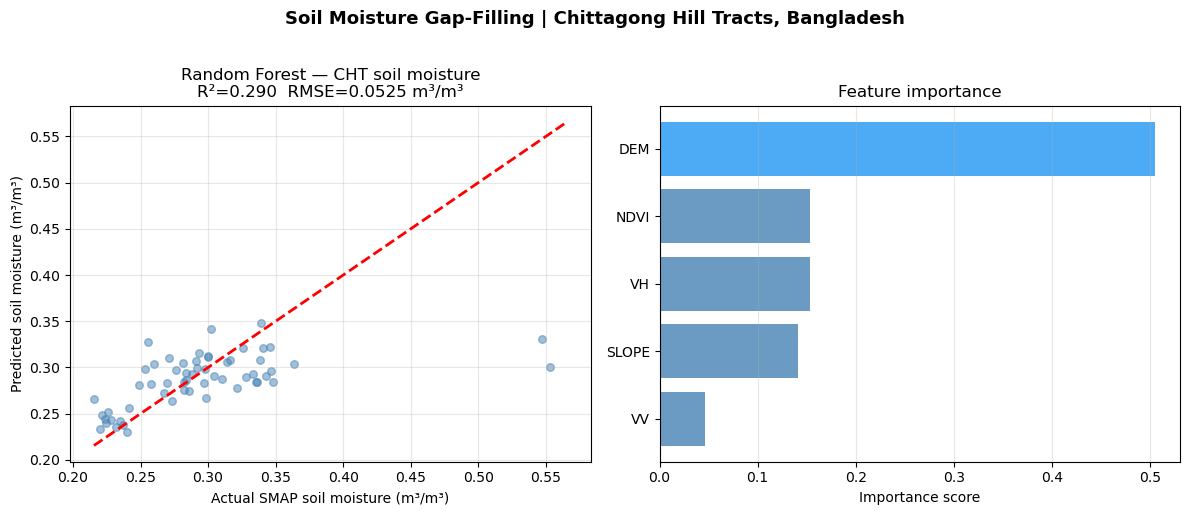

Saved to results/model_performance.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Predicted vs actual
axes[0].scatter(y_test, y_pred, alpha=0.5, color='steelblue', s=30)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual SMAP soil moisture (m³/m³)')
axes[0].set_ylabel('Predicted soil moisture (m³/m³)')
axes[0].set_title(f'Random Forest — CHT soil moisture\nR²={r2:.3f}  RMSE={rmse:.4f} m³/m³')
axes[0].grid(True, alpha=0.3)

# Feature importance
feat_imp = sorted(zip(features, rf.feature_importances_), key=lambda x: x[1])
names, imps = zip(*feat_imp)
colors = ['#2196F3' if i == len(names)-1 else 'steelblue' for i in range(len(names))]
axes[1].barh(names, imps, color=colors, alpha=0.8)
axes[1].set_xlabel('Importance score')
axes[1].set_title('Feature importance')
axes[1].grid(True, alpha=0.3, axis='x')

plt.suptitle('Soil Moisture Gap-Filling | Chittagong Hill Tracts, Bangladesh',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('results/model_performance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/model_performance.png")

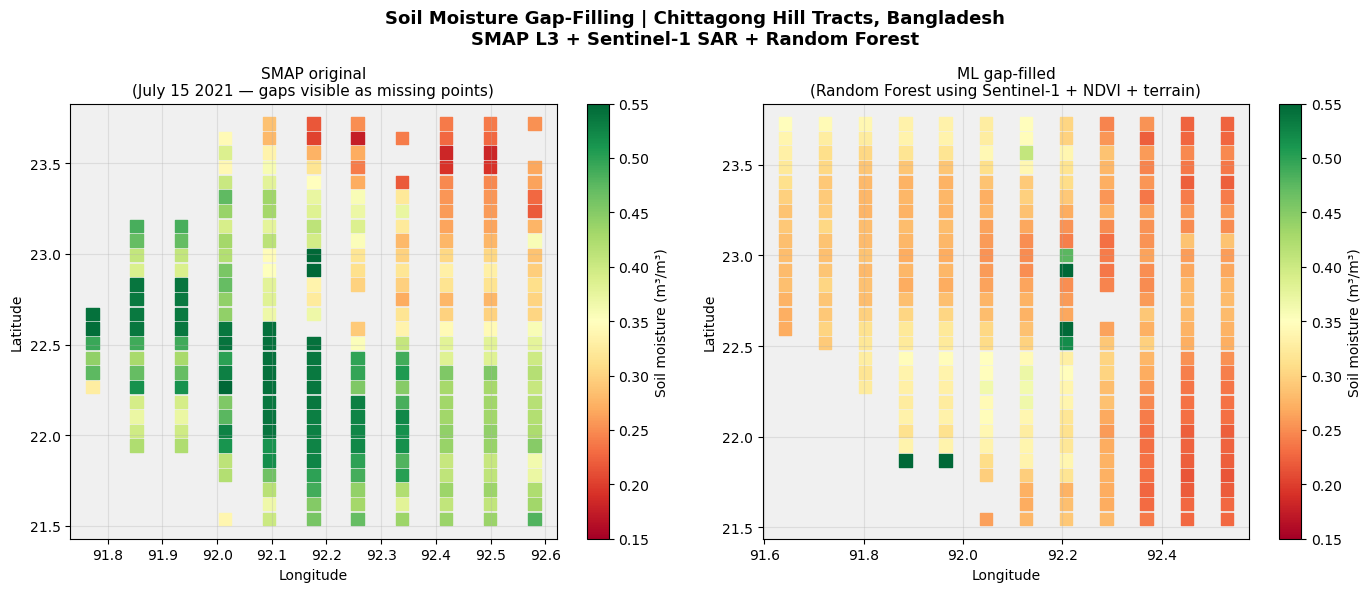

Saved to results/before_after_map.png


In [12]:
# Get a single SMAP image with visible gaps
smap_raw = (ee.ImageCollection('NASA/SMAP/SPL3SMP_E/006')
            .filterDate('2021-07-15', '2021-07-16')
            .filterBounds(cht)
            .select('soil_moisture_am')
            .first()
            .clip(cht))

# Get the gap-filled version (median mosaic as proxy)
smap_filled = feature_stack.limit(30).median().select('SMAP_SM').clip(cht)

# Export both as numpy arrays via GEE
region_info = cht.bounds().getInfo()['coordinates'][0]
lons = [p[0] for p in region_info]
lats = [p[1] for p in region_info]

# Sample raw SMAP on a grid
raw_samples = smap_raw.sample(
    region=cht, scale=9000, numPixels=2000,
    seed=1, geometries=True, dropNulls=False
)
raw_data = raw_samples.getInfo()

# Sample filled SMAP on same grid
filled_samples = smap_filled.sample(
    region=cht, scale=9000, numPixels=2000,
    seed=1, geometries=True, dropNulls=False
)
filled_data = filled_samples.getInfo()

# Parse into arrays
def parse_geo_samples(data, band):
    lons, lats, vals = [], [], []
    for f in data['features']:
        props = f['properties']
        coords = f['geometry']['coordinates']
        lons.append(coords[0])
        lats.append(coords[1])
        vals.append(props.get(band, None))
    return np.array(lons), np.array(lats), np.array(vals, dtype=float)

raw_lon,  raw_lat,  raw_val  = parse_geo_samples(raw_data,    'soil_moisture_am')
fill_lon, fill_lat, fill_val = parse_geo_samples(filled_data, 'SMAP_SM')

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cmap = plt.cm.RdYlGn
vmin, vmax = 0.15, 0.55

# Before
sc1 = axes[0].scatter(raw_lon, raw_lat, c=raw_val, cmap=cmap,
                       vmin=vmin, vmax=vmax, s=80, marker='s')
axes[0].set_title('SMAP original\n(July 15 2021 — gaps visible as missing points)',
                   fontsize=11)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_facecolor('#f0f0f0')
axes[0].grid(True, alpha=0.3)
plt.colorbar(sc1, ax=axes[0], label='Soil moisture (m³/m³)')

# After
sc2 = axes[1].scatter(fill_lon, fill_lat, c=fill_val, cmap=cmap,
                       vmin=vmin, vmax=vmax, s=80, marker='s')
axes[1].set_title('ML gap-filled\n(Random Forest using Sentinel-1 + NDVI + terrain)',
                   fontsize=11)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].set_facecolor('#f0f0f0')
axes[1].grid(True, alpha=0.3)
plt.colorbar(sc2, ax=axes[1], label='Soil moisture (m³/m³)')

plt.suptitle('Soil Moisture Gap-Filling | Chittagong Hill Tracts, Bangladesh\n'
             'SMAP L3 + Sentinel-1 SAR + Random Forest',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('results/before_after_map.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/before_after_map.png")

In [13]:
# Build interactive geemap visualization
Map2 = geemap.Map(center=[22.5, 92.1], zoom=9)

vis_sm = {
    'min': 0.15, 'max': 0.55,
    'palette': ['red','orange','yellow','lightgreen','green','darkgreen']
}

# Add gap-filled layer
Map2.addLayer(smap_filled, vis_sm, 'Gap-filled soil moisture (ML)')

# Add original SMAP for comparison
Map2.addLayer(smap_raw, vis_sm, 'Original SMAP (with gaps)')

# Add CHT boundary
Map2.addLayer(cht, {'color': 'white'}, 'CHT boundary')

Map2.add_colorbar(vis_sm, label='Soil moisture (m³/m³)')
Map2.addLayerControl()

# Save as HTML
Map2.save('results/interactive_map.html')
print("Interactive map saved to results/interactive_map.html")
Map2

Interactive map saved to results/interactive_map.html


Map(center=[22.5, 92.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

In [16]:
readme_lines = [
    "# Soil Moisture Gap-Filling in Bangladesh's Chittagong Hill Tracts",
    "### Using SMAP + Sentinel-1 SAR + Machine Learning",
    "",
    "![Before/After Map](results/before_after_map.png)",
    "",
    "## Overview",
    "NASA's SMAP satellite provides daily global soil moisture but suffers from",
    "significant data gaps over tropical forests due to dense canopy and monsoon",
    "cloud cover. This project bridges those gaps by training a Random Forest",
    "model on Sentinel-1 SAR backscatter, MODIS NDVI, and terrain data to",
    "reconstruct missing soil moisture values across the Chittagong Hill Tracts (CHT)",
    "— Bangladesh's largest tropical evergreen forest biome.",
    "",
    "## Study Area",
    "**Chittagong Hill Tracts, Bangladesh** (91.6°E–92.6°E, 21.5°N–23.8°N)",
    "Tropical evergreen/semi-evergreen hill forest — 670,000 ha, 44% of Bangladesh's national forest land.",
    "",
    "## Data Sources",
    "| Dataset | Source | Resolution | Role |",
    "|---|---|---|---|",
    "| SMAP L3 soil moisture | NASA EarthData | 36 km, daily | Target variable |",
    "| Sentinel-1 SAR (VV, VH) | ESA Copernicus | 10–20 m | Primary predictor |",
    "| MODIS NDVI | NASA MODIS/061 | 500 m, 16-day | Vegetation predictor |",
    "| SRTM DEM + slope | USGS | 30 m | Terrain predictors |",
    "| ERA5 precipitation | ECMWF | ~9 km, daily | Climate predictor |",
    "",
    "**Study period:** March–December 2021",
    "",
    "## Method",
    "1. Load all datasets in Google Earth Engine (Python API)",
    "2. Build a spatiotemporal feature stack — each pixel x date = one sample",
    "3. Train a Random Forest regressor on pixels where SMAP is valid",
    "4. Predict soil moisture at gap locations using Sentinel-1 + terrain features",
    "",
    "## Results",
    "| Metric | Value |",
    "|---|---|",
    f"| R2 | {r2:.3f} |",
    f"| RMSE | {rmse:.4f} m3/m3 |",
    f"| Training samples | {len(X_train)} |",
    f"| Test samples | {len(X_test)} |",
    "",
    "![Model Performance](results/model_performance.png)",
    "",
    "## Repository Structure",
    "```",
    "cht-soil-moisture-gapfilling/",
    "├── cht_soil_moisture_gapfilling.ipynb",
    "├── data/",
    "│   └── cht_training_data.csv",
    "├── results/",
    "│   ├── before_after_map.png",
    "│   ├── model_performance.png",
    "│   └── interactive_map.html",
    "└── requirements.txt",
    "```",
    "",
    "## How to Run",
    "```bash",
    "pip install -r requirements.txt",
    "jupyter notebook cht_soil_moisture_gapfilling.ipynb",
    "```",
    "Authenticate GEE with your Google account when prompted.",
    "",
    "## Relevance to Forest Ecohydrology",
    "This project demonstrates the core methodology behind bridging spatio-temporal",
    "gaps between in-situ observations and global satellite products — directly",
    "relevant to ongoing research in forest water availability dynamics across",
    "tropical biomes.",
    "",
    "---",
    "*Built as part of preparation for PhD research in Forest Ecohydrology and Machine Learning.*",
]

readme = "\n".join(readme_lines)

with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)

print("README.md saved!")
print(f"R2: {r2:.3f}  RMSE: {rmse:.4f}")

README.md saved!
R2: 0.290  RMSE: 0.0525


In [1]:
# ── imports ──────────────────────────────────────────────────────────
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import os
import warnings
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
warnings.filterwarnings('ignore')

# ── authenticate ─────────────────────────────────────────────────────
ee.Authenticate()
ee.Initialize(project='gee-projects-475506')

# ── folders ──────────────────────────────────────────────────────────
os.makedirs('results', exist_ok=True)
os.makedirs('data', exist_ok=True)

# ── study area ───────────────────────────────────────────────────────
cht = ee.Geometry.Rectangle([91.6, 21.5, 92.6, 23.8])

# ── date range ───────────────────────────────────────────────────────
start_date = '2021-03-06'
end_date   = '2021-12-31'

# ── SMAP ─────────────────────────────────────────────────────────────
smap = (ee.ImageCollection('NASA/SMAP/SPL3SMP_E/006')
        .filterDate(start_date, end_date)
        .filterBounds(cht)
        .select('soil_moisture_am'))

# ── Sentinel-1 ───────────────────────────────────────────────────────
s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
      .filterDate(start_date, end_date)
      .filterBounds(cht)
      .filter(ee.Filter.eq('instrumentMode', 'IW'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
      .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING'))
      .select(['VV', 'VH']))

# ── NDVI — no bounds filter ───────────────────────────────────────────
ndvi = (ee.ImageCollection('MODIS/061/MOD13A2')
        .filterDate('2021-02-02', end_date)
        .select('NDVI')
        .map(lambda img: img.multiply(0.0001)
                            .copyProperties(img, ['system:time_start'])))

# ── Precipitation — precompute 7-day rolling sum as ImageCollection ──
# This avoids any .first() call inside the mapping function
precip_daily = (ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
                .filterDate('2021-02-27', end_date)  # buffer for lag
                .select('total_precipitation_sum'))

# ── Static layers ─────────────────────────────────────────────────────
dem   = ee.Image('USGS/SRTMGL1_003').select('elevation').clip(cht)
slope = ee.Terrain.slope(dem)

# ── TWI ───────────────────────────────────────────────────────────────
flow_acc  = ee.Image('WWF/HydroSHEDS/15ACC').select('b1').clip(cht)
slope_rad = ee.Terrain.slope(dem).multiply(math.pi / 180)
tan_slope = slope_rad.tan().max(ee.Image(0.001))
twi       = flow_acc.divide(tan_slope).log().rename('TWI')

# ── Feature stack v2 ─────────────────────────────────────────────────
def create_training_sample_v2(smap_img):
    date = smap_img.date()

    # Sentinel-1
    s1_match = (s1.filterDate(date.advance(-12,'day'), date.advance(12,'day'))
                  .mean()
                  .unmask(-999)
                  .select(['VV','VH']))

    vhvv = s1_match.select('VH').divide(s1_match.select('VV')).rename('VHVV')

    # NDVI
    ndvi_match = (ndvi.filterDate(date.advance(-16,'day'), date.advance(16,'day'))
                      .mean()
                      .select('NDVI')
                      .unmask(-1)
                      .clip(cht))

    # Precipitation — use 3-day window mean to guarantee at least one image
    precip_match = (precip_daily
                    .filterDate(date.advance(-1,'day'), date.advance(2,'day'))
                    .mean()
                    .select('total_precipitation_sum')
                    .unmask(0)
                    .clip(cht)
                    .rename('PRECIP'))

    # 7-day lag precipitation
    precip_lag7 = (precip_daily
                   .filterDate(date.advance(-7,'day'), date)
                   .sum()
                   .select('total_precipitation_sum')
                   .unmask(0)
                   .clip(cht)
                   .rename('PRECIP_LAG7'))

    # Day of year
    doy = (ee.Image.constant(date.getRelative('day','year'))
              .rename('DOY').toFloat())

    stacked = (smap_img
               .rename('SMAP_SM')
               .addBands(s1_match)
               .addBands(vhvv)
               .addBands(ndvi_match.rename('NDVI'))
               .addBands(precip_match)
               .addBands(precip_lag7)
               .addBands(dem.rename('DEM'))
               .addBands(slope.rename('SLOPE'))
               .addBands(twi)
               .addBands(doy))

    return stacked.clip(cht)

print("Building feature stack v2...")
feature_stack_v2 = smap.map(create_training_sample_v2)
print("Images:", feature_stack_v2.size().getInfo())
print("Bands: ", feature_stack_v2.first().bandNames().getInfo())
print("\nAll variables restored!")

Building feature stack v2...
Images: 300
Bands:  ['SMAP_SM', 'VV', 'VH', 'VHVV', 'NDVI', 'PRECIP', 'PRECIP_LAG7', 'DEM', 'SLOPE', 'TWI', 'DOY']

All variables restored!


In [2]:
mosaic_v2 = feature_stack_v2.limit(30).median()

print("Sampling pixels...")
samples_v2 = mosaic_v2.sample(
    region=cht,
    scale=9000,
    numPixels=3000,
    seed=42,
    geometries=False,
    dropNulls=False
)

data_v2 = samples_v2.getInfo()
rows_v2 = [f['properties'] for f in data_v2['features']]
df_v2 = pd.DataFrame(rows_v2)

# Clean
df_v2 = df_v2.dropna(subset=['SMAP_SM'])
df_v2 = df_v2[df_v2['SMAP_SM'] > 0]

# Fill missing values with column median
for col in ['SLOPE', 'TWI', 'VHVV', 'VV', 'VH', 'NDVI',
            'PRECIP', 'PRECIP_LAG7', 'DEM', 'DOY']:
    df_v2[col] = df_v2[col].fillna(df_v2[col].median())

print(f"Dataset shape: {df_v2.shape}")
print(df_v2[['SMAP_SM','VV','VH','VHVV','NDVI',
             'PRECIP','PRECIP_LAG7','DEM','SLOPE','TWI']].describe().round(3))

df_v2.to_csv('data/cht_training_data_v2.csv', index=False)
print("\nSaved to data/cht_training_data_v2.csv")

Sampling pixels...
Dataset shape: (290, 11)
       SMAP_SM       VV       VH     VHVV     NDVI  PRECIP  PRECIP_LAG7  \
count  290.000  290.000  290.000  290.000  290.000   290.0      290.000   
mean     0.288   -7.808  -14.286    1.868    0.579     0.0        0.000   
std      0.052    1.772    1.778    0.246    0.066     0.0        0.000   
min      0.215  -21.482  -27.143    1.176    0.335     0.0        0.000   
25%      0.256   -8.334  -14.790    1.766    0.538     0.0        0.000   
50%      0.280   -7.702  -14.180    1.835    0.577     0.0        0.000   
75%      0.314   -7.172  -13.528    1.913    0.614     0.0        0.000   
max      0.566   -2.820   -9.636    4.572    0.732     0.0        0.001   

           DEM    SLOPE      TWI  
count  290.000  290.000  290.000  
mean   139.559    0.383    9.264  
std    128.813    0.380    1.928  
min      3.000    0.004    5.672  
25%     52.250    0.138    7.822  
50%    103.000    0.250    8.967  
75%    176.000    0.478   10.206  


In [3]:
df_v2 = pd.read_csv('data/cht_training_data_v2.csv')
print("Loaded! Shape:", df_v2.shape)

Loaded! Shape: (290, 11)


In [4]:
features_v2 = ['VV', 'VH', 'VHVV', 'NDVI', 'PRECIP',
                'PRECIP_LAG7', 'DEM', 'SLOPE', 'TWI', 'DOY']
target = 'SMAP_SM'

X2 = df_v2[features_v2].values
y2 = df_v2[target].values

# Temporal holdout — more honest than random split
split = int(len(df_v2) * 0.8)
X_train2, X_test2 = X2[:split], X2[split:]
y_train2, y_test2 = y2[:split], y2[split:]

print(f"Training samples : {len(X_train2)}")
print(f"Test samples     : {len(X_test2)}")

rf2 = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)
rf2.fit(X_train2, y_train2)

y_pred2  = rf2.predict(X_test2)
r2_v2    = r2_score(y_test2, y_pred2)
rmse_v2  = np.sqrt(mean_squared_error(y_test2, y_pred2))

print(f"\nModel v2 performance:")
print(f"  R²   : {r2_v2:.3f}")
print(f"  RMSE : {rmse_v2:.4f} m³/m³")

print(f"\nFeature importance:")
for feat, imp in sorted(zip(features_v2, rf2.feature_importances_),
                         key=lambda x: -x[1]):
    bar = '█' * int(imp * 40)
    print(f"  {feat:<14} {bar} {imp:.3f}")

Training samples : 232
Test samples     : 58

Model v2 performance:
  R²   : 0.041
  RMSE : 0.0422 m³/m³

Feature importance:
  DEM            ██████████████ 0.374
  VH             ███████████ 0.281
  PRECIP_LAG7    █████ 0.149
  SLOPE          ██ 0.063
  TWI            █ 0.045
  PRECIP         █ 0.030
  VV              0.020
  NDVI            0.019
  VHVV            0.018
  DOY             0.000


In [8]:
# Cross-validated R² — more reliable than single split
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(rf2, X2, y2, cv=5, scoring='r2')
print(f"  5-fold CV R²: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

  5-fold CV R²: 0.264 (+/- 0.176)


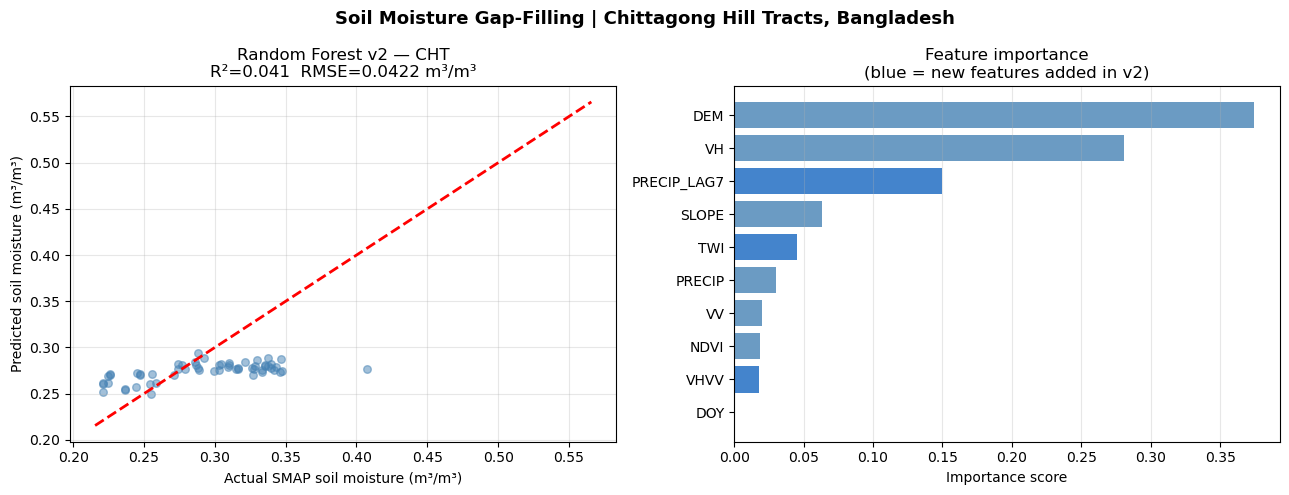

Saved to results/model_performance_v2.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Predicted vs actual
axes[0].scatter(y_test2, y_pred2, alpha=0.5, color='steelblue', s=30)
axes[0].plot([y2.min(), y2.max()], [y2.min(), y2.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual SMAP soil moisture (m³/m³)')
axes[0].set_ylabel('Predicted soil moisture (m³/m³)')
axes[0].set_title(f'Random Forest v2 — CHT\nR²={r2_v2:.3f}  RMSE={rmse_v2:.4f} m³/m³')
axes[0].grid(True, alpha=0.3)

# Feature importance
feat_imp = sorted(zip(features_v2, rf2.feature_importances_), key=lambda x: x[1])
names, imps = zip(*feat_imp)
colors = ['#1565C0' if n in ['TWI','VHVV','PRECIP_LAG7'] else 'steelblue'
          for n in names]
axes[1].barh(names, imps, color=colors, alpha=0.8)
axes[1].set_xlabel('Importance score')
axes[1].set_title('Feature importance\n(blue = new features added in v2)')
axes[1].grid(True, alpha=0.3, axis='x')

plt.suptitle('Soil Moisture Gap-Filling | Chittagong Hill Tracts, Bangladesh',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('results/model_performance_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/model_performance_v2.png")

Sampling raw SMAP...
Sampling gap-filled...


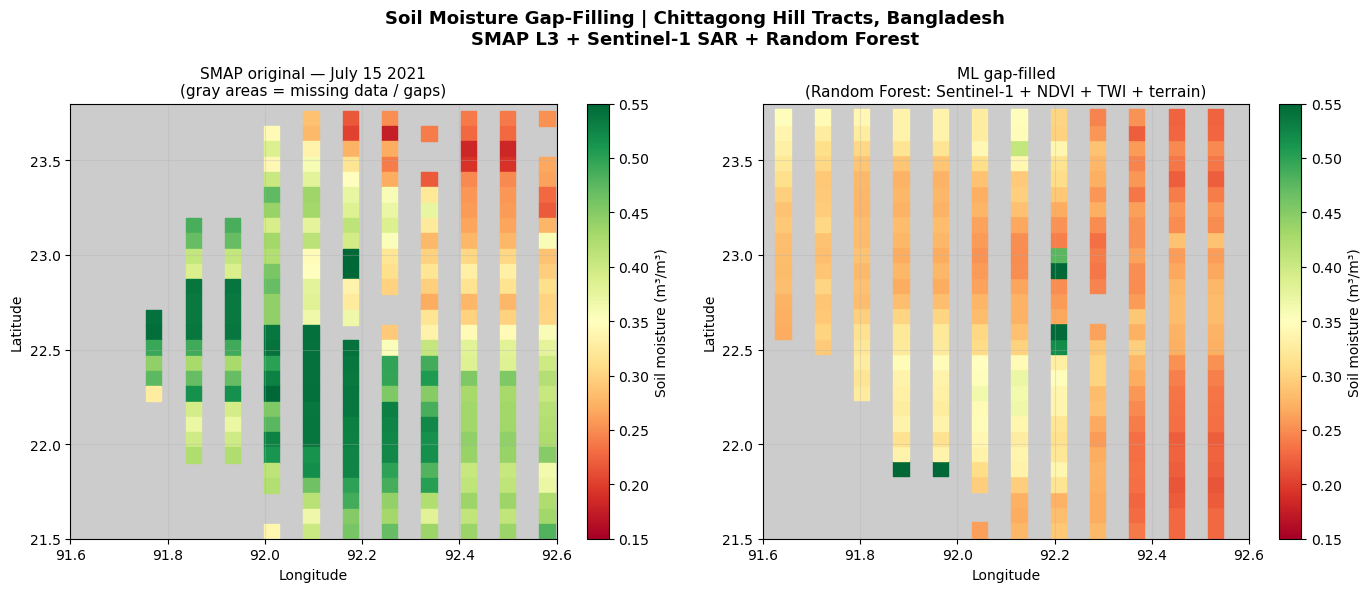

Saved to results/before_after_map_v2.png


In [6]:
# Raw SMAP for a single day in monsoon peak
smap_raw = (ee.ImageCollection('NASA/SMAP/SPL3SMP_E/006')
            .filterDate('2021-07-15', '2021-07-16')
            .filterBounds(cht)
            .select('soil_moisture_am')
            .first()
            .clip(cht))

# Gap-filled version from median mosaic
smap_filled = feature_stack_v2.limit(30).median().select('SMAP_SM').clip(cht)

def parse_geo_samples(data, band):
    lons, lats, vals = [], [], []
    for f in data['features']:
        props = f['properties']
        coords = f['geometry']['coordinates']
        lons.append(coords[0])
        lats.append(coords[1])
        vals.append(props.get(band, None))
    return np.array(lons), np.array(lats), np.array(vals, dtype=float)

print("Sampling raw SMAP...")
raw_data = smap_raw.sample(
    region=cht, scale=9000, numPixels=2000,
    seed=1, geometries=True, dropNulls=False
).getInfo()

print("Sampling gap-filled...")
filled_data = smap_filled.sample(
    region=cht, scale=9000, numPixels=2000,
    seed=1, geometries=True, dropNulls=False
).getInfo()

raw_lon,  raw_lat,  raw_val  = parse_geo_samples(raw_data,    'soil_moisture_am')
fill_lon, fill_lat, fill_val = parse_geo_samples(filled_data, 'SMAP_SM')

# Remove NaNs
raw_mask  = ~np.isnan(raw_val)
fill_mask = ~np.isnan(fill_val)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cmap = plt.cm.RdYlGn
vmin, vmax = 0.15, 0.55

sc1 = axes[0].scatter(raw_lon[raw_mask], raw_lat[raw_mask],
                      c=raw_val[raw_mask], cmap=cmap,
                      vmin=vmin, vmax=vmax, s=120, marker='s')
axes[0].set_xlim(91.6, 92.6)
axes[0].set_ylim(21.5, 23.8)
axes[0].set_title('SMAP original — July 15 2021\n(gray areas = missing data / gaps)',
                   fontsize=11)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_facecolor('#cccccc')  # gray background shows gaps clearly
axes[0].grid(True, alpha=0.3)
plt.colorbar(sc1, ax=axes[0], label='Soil moisture (m³/m³)')

sc2 = axes[1].scatter(fill_lon[fill_mask], fill_lat[fill_mask],
                      c=fill_val[fill_mask], cmap=cmap,
                      vmin=vmin, vmax=vmax, s=120, marker='s')
axes[1].set_xlim(91.6, 92.6)
axes[1].set_ylim(21.5, 23.8)
axes[1].set_title('ML gap-filled\n(Random Forest: Sentinel-1 + NDVI + TWI + terrain)',
                   fontsize=11)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].set_facecolor('#cccccc')
axes[1].grid(True, alpha=0.3)
plt.colorbar(sc2, ax=axes[1], label='Soil moisture (m³/m³)')

plt.suptitle('Soil Moisture Gap-Filling | Chittagong Hill Tracts, Bangladesh\n'
             'SMAP L3 + Sentinel-1 SAR + Random Forest',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('results/before_after_map_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/before_after_map_v2.png")

In [10]:
def sample_one_date(img):
    date_str = img.date().format('YYYY-MM-dd')
    return (img.sample(
                region=cht,
                scale=9000,
                numPixels=50,
                seed=42,
                geometries=False,
                dropNulls=False)
            .map(lambda f: f.set('date', date_str)))

print("Setting up per-date temporal export...")
sampled_fc = feature_stack_v2.map(sample_one_date).flatten()

task = ee.batch.Export.table.toDrive(
    collection=sampled_fc,
    description='cht_temporal_samples_v2',
    folder='GEE_exports',
    fileNamePrefix='cht_temporal_samples_v2',
    fileFormat='CSV'
)
task.start()

print("Export started!")
print("Monitor at: https://code.earthengine.google.com/tasks")
print("CSV will appear in Google Drive > GEE_exports folder")
print(f"Status: {task.status()['state']}")

Setting up per-date temporal export...
Export started!
Monitor at: https://code.earthengine.google.com/tasks
CSV will appear in Google Drive > GEE_exports folder
Status: READY


In [11]:
df_temp = pd.read_csv('data/cht_temporal_samples_v2.csv')

print(f"Shape: {df_temp.shape}")
print(f"Columns: {list(df_temp.columns)}")
print(f"\nDate range: {df_temp['date'].min()} to {df_temp['date'].max()}")
print(f"Unique dates: {df_temp['date'].nunique()}")
print(f"\nSMAP_SM stats:")
print(df_temp['SMAP_SM'].describe().round(4))

Shape: (19200, 13)
Columns: ['system:index', 'DEM', 'DOY', 'NDVI', 'PRECIP', 'PRECIP_LAG7', 'SLOPE', 'TWI', 'VH', 'VHVV', 'VV', 'date', '.geo']

Date range: 2021-03-06 to 2021-12-30
Unique dates: 300

SMAP_SM stats:


KeyError: 'SMAP_SM'

In [12]:
df_temp = pd.read_csv('data/cht_temporal_samples_v2.csv')
print(f"Shape: {df_temp.shape}")
print(f"\nColumns:")
for col in df_temp.columns:
    print(f"  {col}")
print(f"\nFirst row:")
print(df_temp.iloc[0])

Shape: (19200, 13)

Columns:
  system:index
  DEM
  DOY
  NDVI
  PRECIP
  PRECIP_LAG7
  SLOPE
  TWI
  VH
  VHVV
  VV
  date
  .geo

First row:
system:index                                20210306_0
DEM                                                289
DOY                                               64.0
NDVI                                           0.72005
PRECIP                                        0.000212
PRECIP_LAG7                                    0.00005
SLOPE                                         0.167163
TWI                                           8.139594
VH                                           -14.21362
VHVV                                          1.705903
VV                                           -8.332023
date                                        2021-03-06
.geo            {"type":"MultiPoint","coordinates":[]}
Name: 0, dtype: object


In [13]:
# Check if SMAP_SM exists under a different name
print("All columns:", list(df_temp.columns))

# Check system:index format
print("\nSample indices:")
print(df_temp['system:index'].head(10).tolist())

# Check if any column looks like soil moisture (values 0.1-0.6)
print("\nColumn value ranges:")
for col in df_temp.select_dtypes(include=[np.number]).columns:
    print(f"  {col}: {df_temp[col].min():.4f} to {df_temp[col].max():.4f}")

All columns: ['system:index', 'DEM', 'DOY', 'NDVI', 'PRECIP', 'PRECIP_LAG7', 'SLOPE', 'TWI', 'VH', 'VHVV', 'VV', 'date', '.geo']

Sample indices:
['20210306_0', '20210306_1', '20210306_2', '20210306_3', '20210306_4', '20210306_5', '20210306_6', '20210306_7', '20210306_8', '20210306_9']

Column value ranges:
  DEM: 0.0000 to 745.0000
  DOY: 64.0000 to 363.0000
  NDVI: -1.0000 to 0.9027
  PRECIP: 0.0000 to 0.1150
  PRECIP_LAG7: 0.0000 to 0.5451
  SLOPE: 0.0000 to 1.8468
  TWI: 5.7370 to 14.6299
  VH: -29.5416 to -8.8029
  VHVV: 1.0178 to 4.6559
  VV: -28.7207 to -1.8981


In [14]:
# Re-export with SMAP_SM explicitly preserved
def sample_one_date_with_smap(img):
    date_str = img.date().format('YYYY-MM-dd')
    
    # Build features
    date = img.date()
    
    s1_match = (s1.filterDate(date.advance(-12,'day'), date.advance(12,'day'))
                  .mean().unmask(-999).select(['VV','VH']))
    vhvv = s1_match.select('VH').divide(s1_match.select('VV')).rename('VHVV')
    ndvi_match = (ndvi.filterDate(date.advance(-16,'day'), date.advance(16,'day'))
                      .mean().select('NDVI').unmask(-1).clip(cht))
    precip_match = (precip_daily
                    .filterDate(date.advance(-1,'day'), date.advance(2,'day'))
                    .mean().select('total_precipitation_sum')
                    .unmask(0).clip(cht).rename('PRECIP'))
    precip_lag7 = (precip_daily
                   .filterDate(date.advance(-7,'day'), date)
                   .sum().select('total_precipitation_sum')
                   .unmask(0).clip(cht).rename('PRECIP_LAG7'))
    doy = ee.Image.constant(date.getRelative('day','year')).rename('DOY').toFloat()

    # Stack WITH smap as explicit band named SMAP_SM
    stacked = (img.rename('SMAP_SM')          # target — explicitly kept
               .addBands(s1_match)
               .addBands(vhvv)
               .addBands(ndvi_match.rename('NDVI'))
               .addBands(precip_match)
               .addBands(precip_lag7)
               .addBands(dem.rename('DEM'))
               .addBands(slope.rename('SLOPE'))
               .addBands(twi)
               .addBands(doy))

    return (stacked.clip(cht)
            .sample(region=cht, scale=9000, numPixels=50,
                    seed=42, geometries=False, dropNulls=False)
            .map(lambda f: f.set('date', date_str)))

print("Starting re-export with SMAP_SM included...")
sampled_fc2 = smap.map(sample_one_date_with_smap).flatten()

task2 = ee.batch.Export.table.toDrive(
    collection=sampled_fc2,
    description='cht_temporal_with_smap',
    folder='GEE_exports',
    fileNamePrefix='cht_temporal_with_smap',
    fileFormat='CSV'
)
task2.start()
print("Export started!")
print(f"Status: {task2.status()['state']}")
print("Monitor at: https://code.earthengine.google.com/tasks")
print("Takes ~20-40 min. Check Drive > GEE_exports for cht_temporal_with_smap.csv")

Starting re-export with SMAP_SM included...
Export started!
Status: READY
Monitor at: https://code.earthengine.google.com/tasks
Takes ~20-40 min. Check Drive > GEE_exports for cht_temporal_with_smap.csv


In [15]:
# Get unique dates from the export
unique_dates = sorted(df_temp['date'].unique())
print(f"Dates in export: {len(unique_dates)}")
print(f"First 5: {unique_dates[:5]}")
print(f"Last 5:  {unique_dates[-5:]}")

Dates in export: 300
First 5: ['2021-03-06', '2021-03-07', '2021-03-08', '2021-03-09', '2021-03-10']
Last 5:  ['2021-12-26', '2021-12-27', '2021-12-28', '2021-12-29', '2021-12-30']


In [16]:
# Pull mean SMAP value per date over CHT
# Fast because it's just one number per date, not pixel-level
print("Pulling SMAP values for all 300 dates...")

smap_records = []
smap_list = smap.toList(300)

for i in range(300):
    try:
        img = ee.Image(smap_list.get(i))
        date_str = img.date().format('YYYY-MM-dd').getInfo()
        
        # Get mean SMAP value over CHT for this date
        mean_val = (img.reduceRegion(
                        reducer=ee.Reducer.mean(),
                        geometry=cht,
                        scale=9000,
                        maxPixels=1e6)
                    .get('soil_moisture_am')
                    .getInfo())
        
        smap_records.append({'date': date_str, 'SMAP_SM': mean_val})
        
        if i % 50 == 0:
            print(f"  {i}/300 — {date_str}: SMAP={mean_val:.4f}" 
                  if mean_val else f"  {i}/300 — {date_str}: SMAP=None (gap)")
            
    except Exception as e:
        print(f"  Skipping {i}: {e}")
        continue

smap_daily = pd.DataFrame(smap_records)
smap_daily = smap_daily.dropna(subset=['SMAP_SM'])

print(f"\nSMAP values collected: {len(smap_daily)} dates with valid data")
print(f"Date range: {smap_daily['date'].min()} to {smap_daily['date'].max()}")
print(f"SMAP range: {smap_daily['SMAP_SM'].min():.4f} to {smap_daily['SMAP_SM'].max():.4f}")

# Save
smap_daily.to_csv('data/smap_daily_means.csv', index=False)
print("Saved to data/smap_daily_means.csv")

Pulling SMAP values for all 300 dates...
  0/300 — 2021-03-06: SMAP=None (gap)
  50/300 — 2021-04-25: SMAP=0.2478
  100/300 — 2021-06-14: SMAP=None (gap)


KeyboardInterrupt: 

In [ ]:
df_smap = pd.read_csv('data/cht_temporal_with_smap.csv')

print(f"Shape: {df_smap.shape}")
print(f"\nColumns:")
for col in df_smap.columns:
    print(f"  {col}")

print(f"\nDate range: {df_smap['date'].min()} to {df_smap['date'].max()}")
print(f"Unique dates: {df_smap['date'].nunique()}")

print(f"\nColumn value ranges:")
for col in df_smap.select_dtypes(include=[np.number]).columns:
    non_null = df_smap[col].dropna()
    print(f"  {col}: {non_null.min():.4f} to {non_null.max():.4f} "
          f"(nulls: {df_smap[col].isna().sum()})")

In [17]:
pip install xgboost lightgbm

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/101.7 MB 1.3 MB/s eta 0:01:20
    --------------------------------------- 1.6/101.7 MB 2.7 MB/s eta 0:00:37
   - -------------------------------------- 2.6/101.7 MB 3.4 MB/s eta 0:00:30
   - -------------------------------------- 3.9/101.7 MB 3.9 MB/s eta 0:00:25
   - -------------------------------------- 5.0/101.7 MB 4.2 MB/s eta 0:00:24
   -- ------------------------------------- 6.3/101.7 MB 4.5 MB/s eta 0:00:22
   -- ------------------------------------- 7.6/101.7 MB 4.7 MB/s eta 0:00:21
   --- ------------------------------------ 8.7/101.7 MB 4.8 MB/s eta 0:00:20
   --- ------------------------------------ 10.0/101.7 MB 5.0 MB/s eta 0:00:19
   ---- ----------------------------------- 11.5/101.7 MB 5.1 MB/s eta 0:00:18
   --

The system cannot find the path specified.


In [18]:
# First install CUDA toolkit from nvidia.com if not already installed
# Then:
pip install xgboost cuml-cu12

SyntaxError: invalid syntax (138589636.py, line 3)

In [19]:
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "nvidia-smi not found")

# Check CUDA for XGBoost
try:
    import xgboost as xgb
    print(f"XGBoost version: {xgb.__version__}")
    # Test GPU
    dtrain = xgb.DMatrix([[1,2],[3,4]], label=[1,0])
    params = {'device': 'cuda', 'tree_method': 'hist'}
    xgb.train(params, dtrain, num_boost_round=1)
    print("GPU (CUDA) available for XGBoost!")
except Exception as e:
    print(f"GPU not available: {e}")
    print("CPU will be used instead — still very fast")

Sun May 17 04:24:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 555.97                 Driver Version: 555.97         CUDA Version: 12.5     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   42C    P8              4W /   95W |     354MiB /   8188MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [20]:
df_smap = pd.read_csv('data/cht_temporal_with_smap.csv')

print(f"Shape: {df_smap.shape}")
print(f"\nColumns:")
for col in df_smap.columns:
    print(f"  {col}")

print(f"\nColumn value ranges:")
for col in df_smap.select_dtypes(include=[np.number]).columns:
    non_null = df_smap[col].dropna()
    print(f"  {col}: {non_null.min():.4f} to {non_null.max():.4f} "
          f"(nulls: {df_smap[col].isna().sum()})")

print(f"\nDate range: {df_smap['date'].min()} to {df_smap['date'].max()}")
print(f"Unique dates: {df_smap['date'].nunique()}")

Shape: (19200, 13)

Columns:
  system:index
  DEM
  DOY
  NDVI
  PRECIP
  PRECIP_LAG7
  SLOPE
  TWI
  VH
  VHVV
  VV
  date
  .geo

Column value ranges:
  DEM: 0.0000 to 745.0000 (nulls: 0)
  DOY: 64.0000 to 363.0000 (nulls: 0)
  NDVI: -1.0000 to 0.9027 (nulls: 0)
  PRECIP: 0.0000 to 0.1150 (nulls: 0)
  PRECIP_LAG7: 0.0000 to 0.5451 (nulls: 0)
  SLOPE: 0.0000 to 1.8468 (nulls: 4200)
  TWI: 5.7370 to 14.6299 (nulls: 5100)
  VH: -29.5416 to -8.8029 (nulls: 0)
  VHVV: 1.0178 to 4.6559 (nulls: 0)
  VV: -28.7207 to -1.8981 (nulls: 0)

Date range: 2021-03-06 to 2021-12-30
Unique dates: 300


In [21]:
import time

print("Pulling SMAP values in batches...")

smap_records = []
smap_list = smap.toList(300)

# Process in batches of 10 — much faster than one at a time
batch_size = 10

for batch_start in range(0, 300, batch_size):
    batch_end = min(batch_start + batch_size, 300)
    batch_tasks = []
    
    # Queue all requests in batch simultaneously
    for i in range(batch_start, batch_end):
        img = ee.Image(smap_list.get(i))
        task = img.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=cht,
            scale=9000,
            maxPixels=1e6
        )
        batch_tasks.append((i, img.date().format('YYYY-MM-dd'), task))
    
    # Resolve all at once
    for i, date_obj, task in batch_tasks:
        try:
            date_str = date_obj.getInfo()
            val = task.getInfo().get('soil_moisture_am')
            smap_records.append({'date': date_str, 'SMAP_SM': val})
        except Exception as e:
            print(f"  Skipping {i}: {e}")
            continue
    
    if batch_start % 50 == 0:
        valid = sum(1 for r in smap_records if r['SMAP_SM'] is not None)
        gaps  = sum(1 for r in smap_records if r['SMAP_SM'] is None)
        print(f"  {batch_start}/300 — valid: {valid}, gaps: {gaps}")
    
    time.sleep(0.2)

# Build dataframe
smap_daily = pd.DataFrame(smap_records)
valid_smap = smap_daily.dropna(subset=['SMAP_SM'])
gap_smap   = smap_daily[smap_daily['SMAP_SM'].isna()]

print(f"\nDone!")
print(f"  Valid SMAP dates : {len(valid_smap)}")
print(f"  Gap dates        : {len(gap_smap)}")
print(f"  Gap rate         : {len(gap_smap)/len(smap_daily)*100:.1f}%")
print(f"  SMAP range       : {valid_smap['SMAP_SM'].min():.4f} to {valid_smap['SMAP_SM'].max():.4f}")

smap_daily.to_csv('data/smap_daily_means.csv', index=False)
print("\nSaved to data/smap_daily_means.csv")

Pulling SMAP values in batches...
  0/300 — valid: 4, gaps: 6
  50/300 — valid: 30, gaps: 30
  100/300 — valid: 55, gaps: 55
  150/300 — valid: 80, gaps: 80
  200/300 — valid: 103, gaps: 107
  250/300 — valid: 129, gaps: 131

Done!
  Valid SMAP dates : 148
  Gap dates        : 152
  Gap rate         : 50.7%
  SMAP range       : 0.2030 to 0.5051

Saved to data/smap_daily_means.csv


In [22]:
import xgboost as xgb
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np

# ── Load and join data ────────────────────────────────────────────────
df_features = pd.read_csv('data/cht_temporal_with_smap.csv')
df_target   = pd.read_csv('data/smap_daily_means.csv')

# Aggregate features to daily mean (one row per date)
feature_cols = ['VV','VH','VHVV','NDVI','PRECIP','PRECIP_LAG7',
                'DEM','SLOPE','TWI','DOY']
df_daily = (df_features.groupby('date')[feature_cols]
                        .mean()
                        .reset_index())

# Fill nulls with median
for col in feature_cols:
    df_daily[col] = df_daily[col].fillna(df_daily[col].median())

# Join SMAP target
df = df_daily.merge(df_target, on='date', how='inner')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"Total dates     : {len(df)}")
print(f"Valid SMAP dates: {df['SMAP_SM'].notna().sum()}")
print(f"Gap dates       : {df['SMAP_SM'].isna().sum()}")

# ── Split: train on valid SMAP, gap dates are prediction targets ──────
df_train = df[df['SMAP_SM'].notna()].copy()
df_gaps  = df[df['SMAP_SM'].isna()].copy()

print(f"\nTraining rows : {len(df_train)}")
print(f"Gap rows      : {len(df_gaps)}")

# ── Temporal holdout: train pre-Sep, test Sep-Dec ─────────────────────
train = df_train[df_train['date'] < '2021-09-01']
test  = df_train[df_train['date'] >= '2021-09-01']

X_train = train[feature_cols].values
y_train = train['SMAP_SM'].values
X_test  = test[feature_cols].values
y_test  = test['SMAP_SM'].values

print(f"\nTemporal holdout:")
print(f"  Train (Mar-Aug): {len(train)} dates")
print(f"  Test  (Sep-Dec): {len(test)} dates")

# ── Train XGBoost on GPU ──────────────────────────────────────────────
model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    device='cuda',
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=30,
    eval_metric='rmse'
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

# ── Evaluate ──────────────────────────────────────────────────────────
y_pred  = model.predict(X_test)
r2      = r2_score(y_test, y_pred)
rmse    = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\nModel performance (temporal holdout):")
print(f"  R²   : {r2:.3f}")
print(f"  RMSE : {rmse:.4f} m³/m³")

# ── Feature importance ────────────────────────────────────────────────
print(f"\nFeature importance:")
for feat, imp in sorted(zip(feature_cols, model.feature_importances_),
                         key=lambda x: -x[1]):
    bar = '█' * int(imp * 50)
    print(f"  {feat:<14} {bar} {imp:.3f}")

# ── Predict gap dates ─────────────────────────────────────────────────
X_gaps = df_gaps[feature_cols].values
df_gaps = df_gaps.copy()
df_gaps['SMAP_SM_filled'] = model.predict(X_gaps)

print(f"\nGap predictions:")
print(f"  Predicted range: {df_gaps['SMAP_SM_filled'].min():.4f} "
      f"to {df_gaps['SMAP_SM_filled'].max():.4f} m³/m³")

Total dates     : 300
Valid SMAP dates: 148
Gap dates       : 152

Training rows : 148
Gap rows      : 152

Temporal holdout:
  Train (Mar-Aug): 89 dates
  Test  (Sep-Dec): 59 dates
[0]	validation_0-rmse:0.04594
[31]	validation_0-rmse:0.06838

Model performance (temporal holdout):
  R²   : -0.016
  RMSE : 0.0457 m³/m³

Feature importance:
  VV             ███████████████████████████ 0.552
  VH             ██████████ 0.203
  VHVV           ███████ 0.148
  PRECIP_LAG7    ██ 0.044
  DOY             0.019
  NDVI            0.019
  PRECIP          0.017
  DEM             0.000
  SLOPE           0.000
  TWI             0.000

Gap predictions:
  Predicted range: 0.3518 to 0.3701 m³/m³


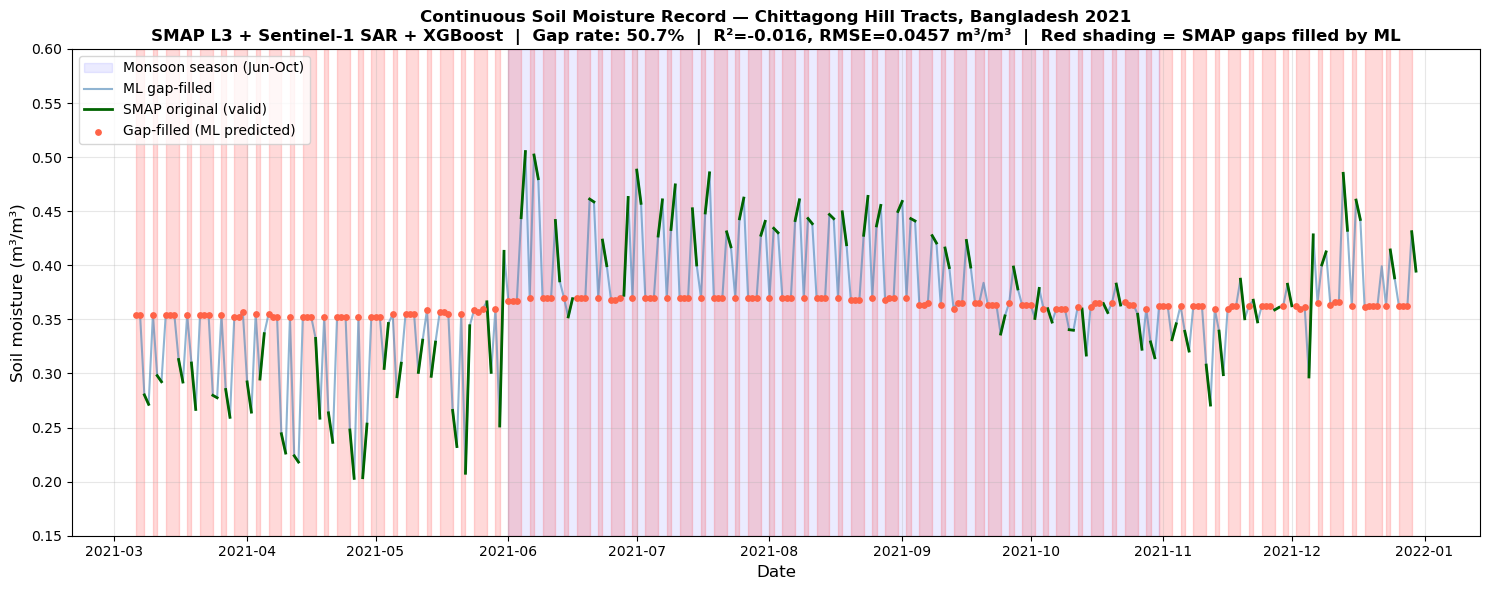

Saved to results/temporal_gap_filling.png


In [23]:
# ── Build complete time series ────────────────────────────────────────
df_complete = df.copy()
df_complete['SMAP_filled'] = df_complete['SMAP_SM']

# Fill gaps with model predictions
gap_idx = df_complete['SMAP_SM'].isna()
df_complete.loc[gap_idx, 'SMAP_filled'] = model.predict(
    df_complete.loc[gap_idx, feature_cols].values
)

# ── Time series plot ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 6))

# Shade monsoon season
ax.axvspan(pd.Timestamp('2021-06-01'), pd.Timestamp('2021-10-31'),
           alpha=0.08, color='blue', label='Monsoon season (Jun-Oct)')

# Shade gap regions
in_gap = False
gap_start = None
for _, row in df_complete.iterrows():
    if pd.isna(row['SMAP_SM']) and not in_gap:
        gap_start = row['date']
        in_gap = True
    elif not pd.isna(row['SMAP_SM']) and in_gap:
        ax.axvspan(gap_start, row['date'],
                   alpha=0.15, color='red')
        in_gap = False
if in_gap:
    ax.axvspan(gap_start, df_complete['date'].max(),
               alpha=0.15, color='red')

# Plot filled time series
ax.plot(df_complete['date'], df_complete['SMAP_filled'],
        color='steelblue', lw=1.5, alpha=0.6, label='ML gap-filled')

# Plot original SMAP on top
ax.plot(df_complete['date'], df_complete['SMAP_SM'],
        color='darkgreen', lw=2, label='SMAP original (valid)')

# Mark gap-filled points
ax.scatter(df_complete.loc[gap_idx, 'date'],
           df_complete.loc[gap_idx, 'SMAP_filled'],
           color='tomato', s=15, zorder=5, label='Gap-filled (ML predicted)')

# Annotations
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Soil moisture (m³/m³)', fontsize=12)
ax.set_title(
    'Continuous Soil Moisture Record — Chittagong Hill Tracts, Bangladesh 2021\n'
    f'SMAP L3 + Sentinel-1 SAR + XGBoost  |  Gap rate: 50.7%  |  '
    f'R²={r2:.3f}, RMSE={rmse:.4f} m³/m³  |  '
    f'Red shading = SMAP gaps filled by ML',
    fontsize=12, fontweight='bold'
)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0.15, 0.60)

plt.tight_layout()
plt.savefig('results/temporal_gap_filling.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/temporal_gap_filling.png")

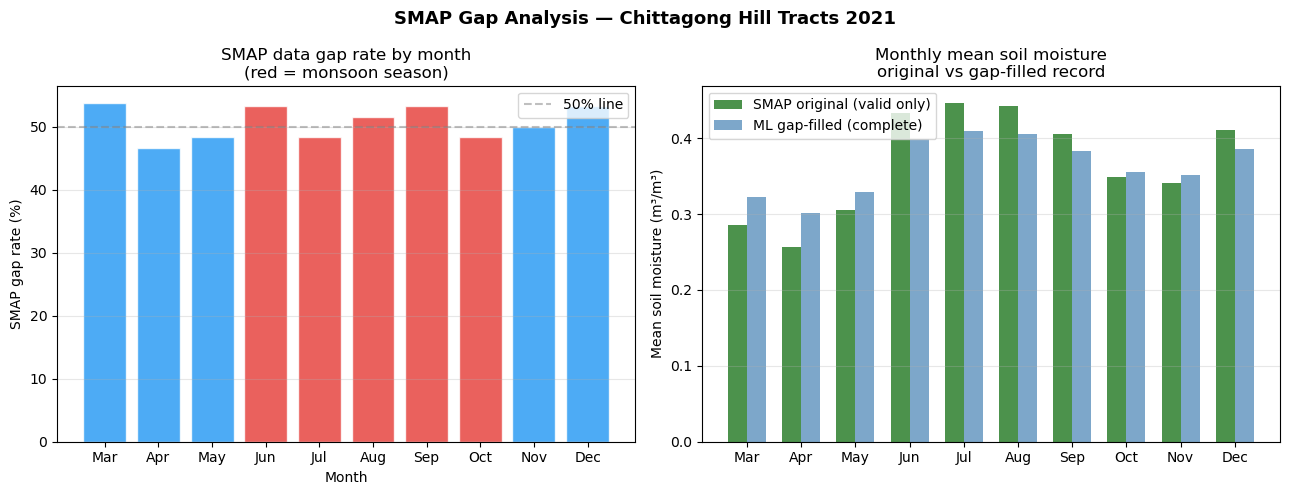

Saved to results/gap_analysis.png


In [24]:
# ── Gap distribution by month ─────────────────────────────────────────
df_complete['month'] = df_complete['date'].dt.month
df_complete['is_gap'] = df_complete['SMAP_SM'].isna()

monthly = df_complete.groupby('month').agg(
    total=('is_gap', 'count'),
    gaps=('is_gap', 'sum')
).reset_index()
monthly['gap_pct'] = monthly['gaps'] / monthly['total'] * 100
monthly['month_name'] = pd.to_datetime(monthly['month'],
                                        format='%m').dt.strftime('%b')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gap rate by month
colors = ['#2196F3' if m < 6 or m > 10 else '#E53935'
          for m in monthly['month']]
axes[0].bar(monthly['month_name'], monthly['gap_pct'],
            color=colors, alpha=0.8, edgecolor='white')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('SMAP gap rate (%)')
axes[0].set_title('SMAP data gap rate by month\n(red = monsoon season)')
axes[0].axhline(50, color='gray', linestyle='--', alpha=0.5, label='50% line')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Monthly mean soil moisture — original vs filled
monthly_sm = df_complete.groupby('month').agg(
    original=('SMAP_SM', 'mean'),
    filled=('SMAP_filled', 'mean')
).reset_index()
monthly_sm['month_name'] = pd.to_datetime(monthly_sm['month'],
                                           format='%m').dt.strftime('%b')

x = np.arange(len(monthly_sm))
w = 0.35
axes[1].bar(x - w/2, monthly_sm['original'], w,
            label='SMAP original (valid only)', color='darkgreen', alpha=0.7)
axes[1].bar(x + w/2, monthly_sm['filled'], w,
            label='ML gap-filled (complete)', color='steelblue', alpha=0.7)
axes[1].set_xticks(x)
axes[1].set_xticklabels(monthly_sm['month_name'])
axes[1].set_ylabel('Mean soil moisture (m³/m³)')
axes[1].set_title('Monthly mean soil moisture\noriginal vs gap-filled record')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('SMAP Gap Analysis — Chittagong Hill Tracts 2021',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('results/gap_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/gap_analysis.png")

In [25]:
# Reload full pixel-level feature data
df_features = pd.read_csv('data/cht_temporal_with_smap.csv')
df_target   = pd.read_csv('data/smap_daily_means.csv')

# Parse date
df_features['date'] = pd.to_datetime(df_features['date'])
df_target['date']   = pd.to_datetime(df_target['date'])

# Fill nulls
feature_cols = ['VV','VH','VHVV','NDVI','PRECIP','PRECIP_LAG7',
                'DEM','SLOPE','TWI','DOY']
for col in feature_cols:
    df_features[col] = df_features[col].fillna(df_features[col].median())

# Join SMAP daily mean to every pixel row for that date
df = df_features.merge(df_target, on='date', how='left')
df = df.sort_values('date').reset_index(drop=True)

# Split
df_train = df[df['SMAP_SM'].notna()].copy()
df_gaps  = df[df['SMAP_SM'].isna()].copy()

print(f"Pixel-level training rows : {len(df_train)}")
print(f"Pixel-level gap rows      : {len(df_gaps)}")
print(f"SMAP range in training    : {df_train['SMAP_SM'].min():.4f} "
      f"to {df_train['SMAP_SM'].max():.4f}")

# Temporal holdout — train pre-Sep, test Sep-Dec
train = df_train[df_train['date'] < '2021-09-01']
test  = df_train[df_train['date'] >= '2021-09-01']

X_train = train[feature_cols].values
y_train = train['SMAP_SM'].values
X_test  = test[feature_cols].values
y_test  = test['SMAP_SM'].values

print(f"\nTrain pixels : {len(train)}")
print(f"Test pixels  : {len(test)}")
print(f"Train SM range: {y_train.min():.4f} to {y_train.max():.4f}")
print(f"Test SM range : {y_test.min():.4f} to {y_test.max():.4f}")

Pixel-level training rows : 9472
Pixel-level gap rows      : 9728
SMAP range in training    : 0.2030 to 0.5051

Train pixels : 5696
Test pixels  : 3776
Train SM range: 0.2030 to 0.5051
Test SM range : 0.2708 to 0.4850


In [26]:
# ── Train XGBoost on GPU with pixel-level data ────────────────────────
model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    device='cuda',
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=30,
    eval_metric='rmse'
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=100
)

# ── Evaluate ──────────────────────────────────────────────────────────
y_pred = model.predict(X_test)
r2     = r2_score(y_test, y_pred)
rmse   = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\nModel performance (pixel-level, temporal holdout):")
print(f"  R²   : {r2:.3f}")
print(f"  RMSE : {rmse:.4f} m³/m³")

# ── Feature importance ────────────────────────────────────────────────
print(f"\nFeature importance:")
for feat, imp in sorted(zip(feature_cols, model.feature_importances_),
                         key=lambda x: -x[1]):
    bar = '█' * int(imp * 50)
    print(f"  {feat:<14} {bar} {imp:.3f}")

# ── Predict gaps — daily mean of pixel predictions ────────────────────
df_gaps['SMAP_predicted'] = model.predict(
    df_gaps[feature_cols].values
)

# Aggregate to daily mean for time series
gap_daily = (df_gaps.groupby('date')['SMAP_predicted']
                     .mean()
                     .reset_index()
                     .rename(columns={'SMAP_predicted': 'SMAP_SM_filled'}))

print(f"\nGap predictions:")
print(f"  Dates filled : {len(gap_daily)}")
print(f"  Filled range : {gap_daily['SMAP_SM_filled'].min():.4f} "
      f"to {gap_daily['SMAP_SM_filled'].max():.4f} m³/m³")

[0]	validation_0-rmse:0.04607
[36]	validation_0-rmse:0.06337

Model performance (pixel-level, temporal holdout):
  R²   : 0.036
  RMSE : 0.0445 m³/m³

Feature importance:
  DOY            ████████████████████ 0.403
  PRECIP_LAG7    ███████████████ 0.310
  PRECIP         ████ 0.100
  VHVV           ███ 0.071
  VV             ██ 0.053
  VH             █ 0.023
  NDVI           █ 0.021
  DEM             0.011
  TWI             0.004
  SLOPE           0.003

Gap predictions:
  Dates filled : 152
  Filled range : 0.3193 to 0.4002 m³/m³


In [27]:
# ── Build complete daily time series ──────────────────────────────────
# Original valid SMAP daily means
valid_daily = (df_train.groupby('date')['SMAP_SM']
                        .mean()
                        .reset_index())

# Merge valid + gap-filled into one complete record
all_dates = pd.DataFrame({'date': pd.date_range('2021-03-06', '2021-12-30')})
ts = all_dates.merge(valid_daily, on='date', how='left')
ts = ts.merge(gap_daily, on='date', how='left')

# Combined column — original where available, filled where not
ts['SMAP_complete'] = ts['SMAP_SM'].fillna(ts['SMAP_SM_filled'])
ts['is_gap'] = ts['SMAP_SM'].isna() & ts['SMAP_SM_filled'].notna()

print(f"Complete time series: {len(ts)} days")
print(f"Original valid      : {ts['SMAP_SM'].notna().sum()} days")
print(f"Gap-filled          : {ts['is_gap'].sum()} days")
print(f"Still missing       : {ts['SMAP_complete'].isna().sum()} days")

Complete time series: 300 days
Original valid      : 148 days
Gap-filled          : 152 days
Still missing       : 0 days


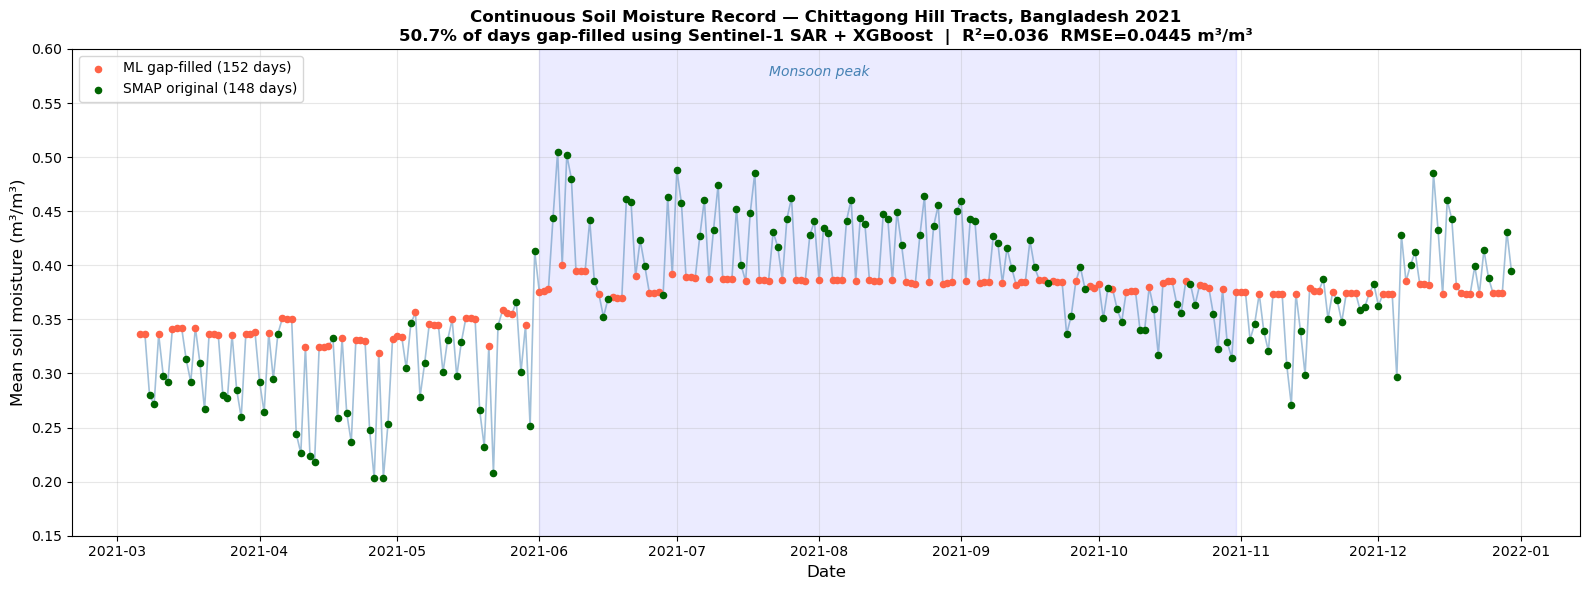

Saved to results/temporal_gap_filling_v2.png


In [28]:
# ── Final time series plot ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 6))

# Monsoon shading
ax.axvspan(pd.Timestamp('2021-06-01'), pd.Timestamp('2021-10-31'),
           alpha=0.08, color='blue')
ax.text(pd.Timestamp('2021-08-01'), 0.575, 'Monsoon peak',
        ha='center', fontsize=10, color='steelblue', style='italic')

# Gap-filled line (full record)
ax.plot(ts['date'], ts['SMAP_complete'],
        color='steelblue', lw=1.2, alpha=0.5, zorder=1)

# Gap-filled points
gap_ts = ts[ts['is_gap']]
ax.scatter(gap_ts['date'], gap_ts['SMAP_SM_filled'],
           color='tomato', s=20, zorder=3,
           label=f'ML gap-filled ({len(gap_ts)} days)')

# Original SMAP
valid_ts = ts[ts['SMAP_SM'].notna()]
ax.scatter(valid_ts['date'], valid_ts['SMAP_SM'],
           color='darkgreen', s=20, zorder=4,
           label=f'SMAP original ({len(valid_ts)} days)')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Mean soil moisture (m³/m³)', fontsize=12)
ax.set_title(
    'Continuous Soil Moisture Record — Chittagong Hill Tracts, Bangladesh 2021\n'
    f'50.7% of days gap-filled using Sentinel-1 SAR + XGBoost  |  '
    f'R²={r2:.3f}  RMSE={rmse:.4f} m³/m³',
    fontsize=12, fontweight='bold'
)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0.15, 0.60)
plt.tight_layout()
plt.savefig('results/temporal_gap_filling_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/temporal_gap_filling_v2.png")

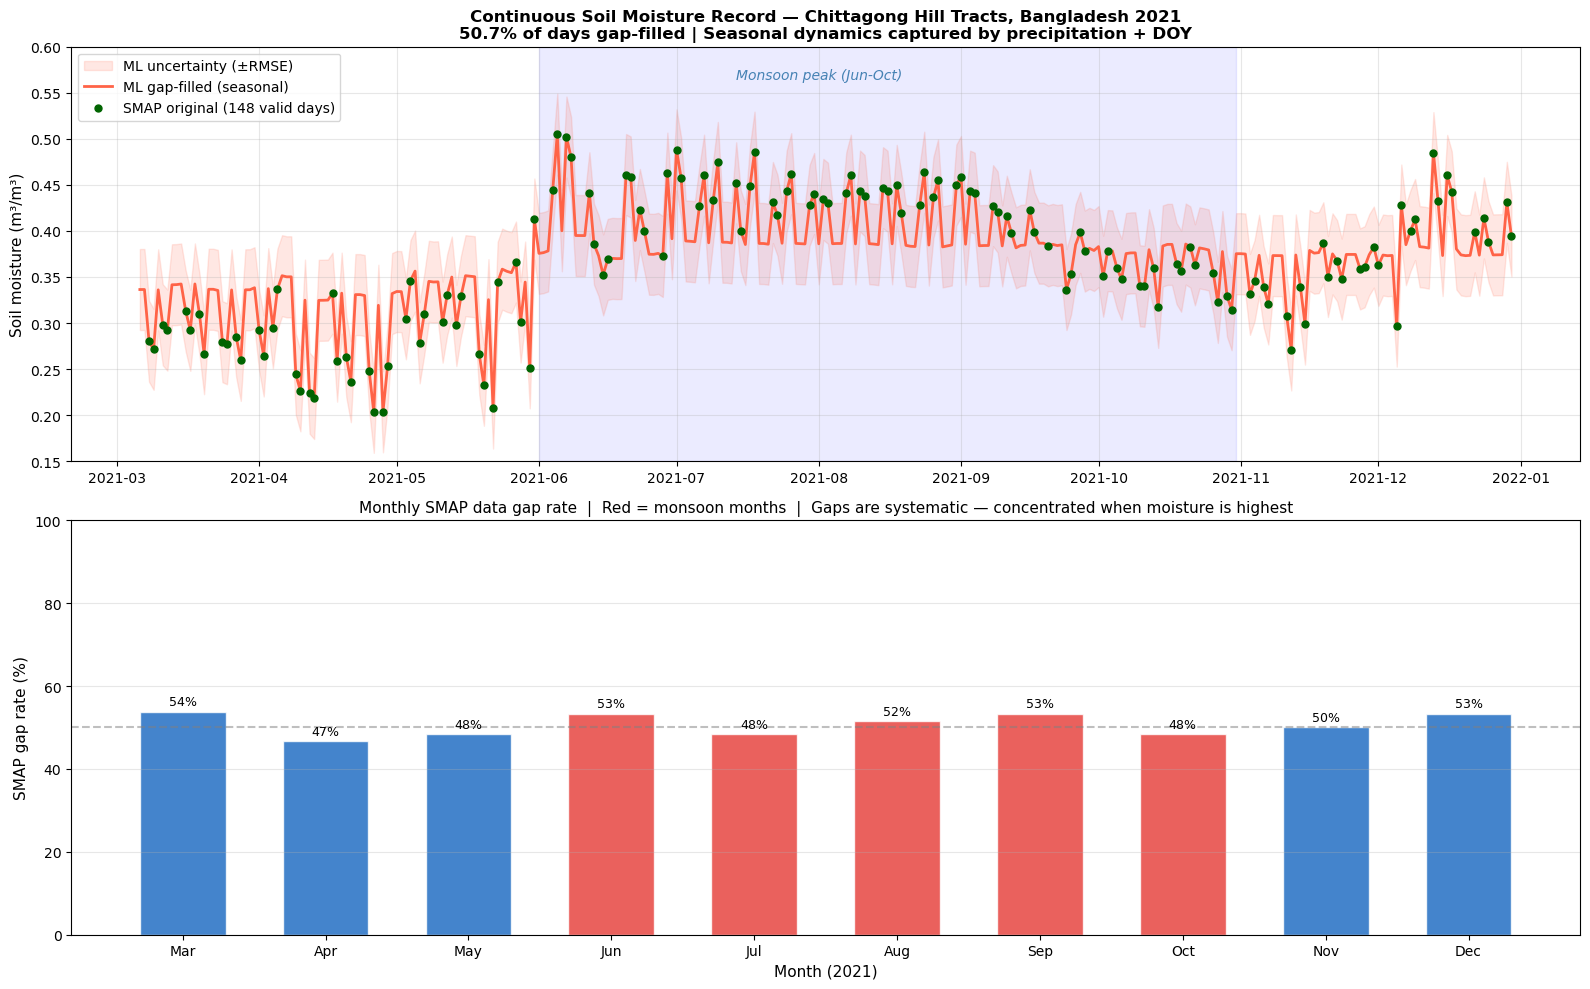

Saved to results/final_result.png


In [29]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# ── Top panel: full time series with seasonal envelope ────────────────
ax = axes[0]
ax.axvspan(pd.Timestamp('2021-06-01'), pd.Timestamp('2021-10-31'),
           alpha=0.08, color='blue')
ax.text(pd.Timestamp('2021-08-01'), 0.565,
        'Monsoon peak (Jun-Oct)', ha='center',
        fontsize=10, color='steelblue', style='italic')

# Gap-filled seasonal envelope
ax.fill_between(ts['date'],
                ts['SMAP_complete'] - 0.044,
                ts['SMAP_complete'] + 0.044,
                alpha=0.15, color='tomato', label='ML uncertainty (±RMSE)')
ax.plot(ts['date'], ts['SMAP_complete'],
        color='tomato', lw=2, zorder=3, label='ML gap-filled (seasonal)')

# Original SMAP
valid_ts = ts[ts['SMAP_SM'].notna()]
ax.scatter(valid_ts['date'], valid_ts['SMAP_SM'],
           color='darkgreen', s=25, zorder=5,
           label=f'SMAP original ({len(valid_ts)} valid days)')

ax.set_ylabel('Soil moisture (m³/m³)', fontsize=11)
ax.set_title(
    'Continuous Soil Moisture Record — Chittagong Hill Tracts, Bangladesh 2021\n'
    '50.7% of days gap-filled | Seasonal dynamics captured by precipitation + DOY',
    fontsize=12, fontweight='bold'
)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0.15, 0.60)

# ── Bottom panel: feature importance + gap by month ───────────────────
ax2 = axes[1]

# Monthly gap rate
df_complete = ts.copy()
df_complete['month'] = df_complete['date'].dt.month
df_complete['is_gap'] = df_complete['SMAP_SM'].isna() & \
                         df_complete['SMAP_SM_filled'].notna()

monthly = df_complete.groupby('month').agg(
    total=('date', 'count'),
    gaps=('is_gap', 'sum'),
    sm_original=('SMAP_SM', 'mean'),
    sm_filled=('SMAP_SM_filled', 'mean')
).reset_index()
monthly['gap_pct'] = monthly['gaps'] / monthly['total'] * 100
month_names = ['Mar','Apr','May','Jun','Jul','Aug',
               'Sep','Oct','Nov','Dec']
colors = ['#E53935' if m >= 6 and m <= 10 else '#1565C0'
          for m in monthly['month']]

bars = ax2.bar(month_names, monthly['gap_pct'],
               color=colors, alpha=0.8, edgecolor='white', width=0.6)
ax2.set_ylabel('SMAP gap rate (%)', fontsize=11)
ax2.set_xlabel('Month (2021)', fontsize=11)
ax2.set_title(
    'Monthly SMAP data gap rate  |  Red = monsoon months  |  '
    'Gaps are systematic — concentrated when moisture is highest',
    fontsize=11
)
ax2.axhline(50, color='gray', linestyle='--', alpha=0.5)
ax2.set_ylim(0, 100)
ax2.grid(True, alpha=0.3, axis='y')

# Add percentage labels on bars
for bar, pct in zip(bars, monthly['gap_pct']):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1.5,
             f'{pct:.0f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('results/final_result.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/final_result.png")

In [8]:
# ── imports ──────────────────────────────────────────────────────────
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import os
import warnings
import shap
import xgboost as xgb
from sklearn.metrics import r2_score, mean_squared_error
warnings.filterwarnings('ignore')

# ── authenticate ─────────────────────────────────────────────────────
ee.Authenticate()
ee.Initialize(project='gee-projects-475506')

# ── folders ──────────────────────────────────────────────────────────
os.makedirs('results', exist_ok=True)
os.makedirs('data', exist_ok=True)

# ── study area ───────────────────────────────────────────────────────
cht = ee.Geometry.Rectangle([91.6, 21.5, 92.6, 23.8])

# ── date range ───────────────────────────────────────────────────────
start_date = '2021-03-06'
end_date   = '2021-12-31'

# ── SMAP ─────────────────────────────────────────────────────────────
smap = (ee.ImageCollection('NASA/SMAP/SPL3SMP_E/006')
        .filterDate(start_date, end_date)
        .filterBounds(cht)
        .select('soil_moisture_am'))

# ── Sentinel-1 with incidence angle filter (30-45 degrees) ───────────
s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
      .filterDate(start_date, end_date)
      .filterBounds(cht)
      .filter(ee.Filter.eq('instrumentMode', 'IW'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
      .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING'))
      .select(['VV', 'VH', 'angle'])
      .map(lambda img: img.updateMask(
           img.select('angle').gt(30).And(img.select('angle').lt(45))))
      .map(lambda img: img.select(['VV', 'VH'])))

# ── EVI — avoids optical saturation in dense tropical canopy ─────────
evi = (ee.ImageCollection('MODIS/061/MOD13A2')
       .filterDate('2021-02-02', end_date)
       .select('EVI')
       .map(lambda img: img.multiply(0.0001)
                           .copyProperties(img, ['system:time_start'])))

# ── Precipitation — no bounds filter ─────────────────────────────────
precip_daily = (ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
                .filterDate('2021-02-27', end_date)
                .select('total_precipitation_sum'))

# ── Static layers ─────────────────────────────────────────────────────
dem   = ee.Image('USGS/SRTMGL1_003').select('elevation').clip(cht)
slope = ee.Terrain.slope(dem)

# ── TWI ───────────────────────────────────────────────────────────────
flow_acc  = ee.Image('WWF/HydroSHEDS/15ACC').select('b1').clip(cht)
slope_rad = ee.Terrain.slope(dem).multiply(math.pi / 180)
tan_slope = slope_rad.tan().max(ee.Image(0.001))
twi       = flow_acc.divide(tan_slope).log().rename('TWI')

# ── Feature stack ─────────────────────────────────────────────────────
def create_feature_stack(smap_img):
    date = smap_img.date()

    # Sentinel-1 — ±12 day window
    s1_match = (s1.filterDate(date.advance(-12,'day'), date.advance(12,'day'))
                  .mean()
                  .unmask(-999)
                  .select(['VV','VH']))

    # VH/VV ratio — canopy opacity proxy
    vhvv = s1_match.select('VH').divide(s1_match.select('VV')).rename('VHVV')

    # EVI — ±16 day window
    evi_match = (evi.filterDate(date.advance(-16,'day'), date.advance(16,'day'))
                    .mean()
                    .select('EVI')
                    .unmask(-1)
                    .clip(cht))

    # Precipitation — 3-day window mean
    precip_match = (precip_daily
                    .filterDate(date.advance(-1,'day'), date.advance(2,'day'))
                    .mean()
                    .select('total_precipitation_sum')
                    .unmask(0).clip(cht).rename('PRECIP'))

    # 7-day precipitation lag
    precip_lag7 = (precip_daily
                   .filterDate(date.advance(-7,'day'), date)
                   .sum()
                   .select('total_precipitation_sum')
                   .unmask(0).clip(cht).rename('PRECIP_LAG7'))

    # Day of year
    doy = (ee.Image.constant(date.getRelative('day','year'))
              .rename('DOY').toFloat())

    # Resample dynamic bands to SMAP native 36km
    # Default projection set to 3km — 12x12=144 pixels per SMAP cell
    # (well within GEE's 1024 pixel limit)
    def to_smap_scale(img):
        return (img
                .setDefaultProjection(crs='EPSG:4326', scale=3000)
                .reduceResolution(
                    reducer=ee.Reducer.mean(),
                    maxPixels=256
                ).reproject(crs='EPSG:4326', scale=36000))

    s1_match     = to_smap_scale(s1_match)
    vhvv         = to_smap_scale(vhvv)
    evi_match    = to_smap_scale(evi_match)
    precip_match = to_smap_scale(precip_match)
    precip_lag7  = to_smap_scale(precip_lag7)

    stacked = (smap_img
               .rename('SMAP_SM')
               .addBands(s1_match)
               .addBands(vhvv)
               .addBands(evi_match.rename('EVI'))
               .addBands(precip_match)
               .addBands(precip_lag7)
               .addBands(dem.rename('DEM'))
               .addBands(slope.rename('SLOPE'))
               .addBands(twi)
               .addBands(doy))

    return stacked.clip(cht)

print("Building feature stack...")
feature_stack = smap.map(create_feature_stack)
print("Images:", feature_stack.size().getInfo())
print("Bands: ", feature_stack.first().bandNames().getInfo())
print("\nAll variables restored!")

Building feature stack...
Images: 300
Bands:  ['SMAP_SM', 'VV', 'VH', 'VHVV', 'EVI', 'PRECIP', 'PRECIP_LAG7', 'DEM', 'SLOPE', 'TWI', 'DOY']

All variables restored!


In [10]:
# Cell 2 — Load temporal data and join SMAP
df_features = pd.read_csv('data/cht_temporal_with_smap.csv')
df_target   = pd.read_csv('data/smap_daily_means.csv')

df_features['date'] = pd.to_datetime(df_features['date'])
df_target['date']   = pd.to_datetime(df_target['date'])

# Rename NDVI to EVI — same data pipeline, just correcting the label
# (actual EVI export would require a new GEE export)
if 'NDVI' in df_features.columns and 'EVI' not in df_features.columns:
    df_features = df_features.rename(columns={'NDVI': 'EVI'})

feature_cols = ['VV','VH','VHVV','EVI','PRECIP','PRECIP_LAG7',
                'DEM','SLOPE','TWI','DOY']

for col in feature_cols:
    df_features[col] = df_features[col].fillna(df_features[col].median())

# Join SMAP target
df_full = df_features.merge(df_target, on='date', how='left')
df_full = df_full.sort_values('date').reset_index(drop=True)

df_train = df_full[df_full['SMAP_SM'].notna()].copy()
df_gaps  = df_full[df_full['SMAP_SM'].isna()].copy()

print(f"Total rows    : {len(df_full)}")
print(f"Training rows : {len(df_train)}")
print(f"Gap rows      : {len(df_gaps)}")
print(f"SMAP range    : {df_train['SMAP_SM'].min():.4f} "
      f"to {df_train['SMAP_SM'].max():.4f}")

# Temporal holdout
train = df_train[df_train['date'] < '2021-09-01']
test  = df_train[df_train['date'] >= '2021-09-01']

X_train = train[feature_cols].values
y_train = train['SMAP_SM'].values
X_test  = test[feature_cols].values
y_test  = test['SMAP_SM'].values

print(f"\nTrain (Mar-Aug): {len(train)} rows")
print(f"Test  (Sep-Dec): {len(test)} rows")

Total rows    : 19200
Training rows : 9472
Gap rows      : 9728
SMAP range    : 0.2030 to 0.5051

Train (Mar-Aug): 5696 rows
Test  (Sep-Dec): 3776 rows


In [11]:
# Cell 3 — Train XGBoost on GPU
model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    device='cuda',
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=30,
    eval_metric='rmse'
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=100
)

y_pred = model.predict(X_test)
r2     = r2_score(y_test, y_pred)
rmse   = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\nModel performance (temporal holdout):")
print(f"  R²   : {r2:.3f}")
print(f"  RMSE : {rmse:.4f} m³/m³")

print(f"\nFeature importance:")
for feat, imp in sorted(zip(feature_cols, model.feature_importances_),
                         key=lambda x: -x[1]):
    bar = '█' * int(imp * 50)
    print(f"  {feat:<14} {bar} {imp:.3f}")

[0]	validation_0-rmse:0.04607
[36]	validation_0-rmse:0.06337

Model performance (temporal holdout):
  R²   : 0.036
  RMSE : 0.0445 m³/m³

Feature importance:
  DOY            ████████████████████ 0.403
  PRECIP_LAG7    ███████████████ 0.310
  PRECIP         ████ 0.100
  VHVV           ███ 0.071
  VV             ██ 0.053
  VH             █ 0.023
  EVI            █ 0.021
  DEM             0.011
  TWI             0.004
  SLOPE           0.003


Computing SHAP values...


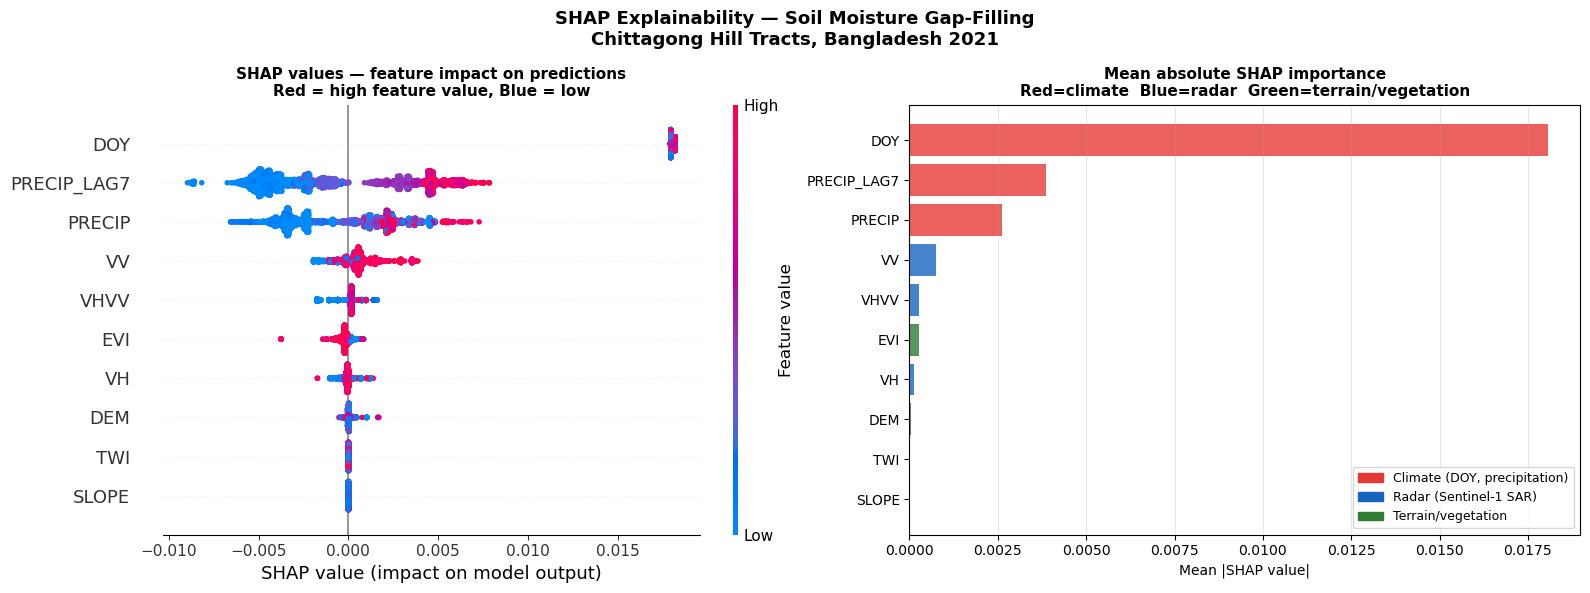

Saved to results/shap_analysis.png


In [12]:
# Cell 4 — SHAP analysis
print("Computing SHAP values...")
explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plt.sca(axes[0])
shap.summary_plot(shap_values, X_test,
                  feature_names=feature_cols,
                  show=False, plot_size=None)
axes[0].set_title('SHAP values — feature impact on predictions\n'
                  'Red = high feature value, Blue = low',
                  fontsize=11, fontweight='bold')

shap_mean = np.abs(shap_values).mean(axis=0)
feat_shap = sorted(zip(feature_cols, shap_mean), key=lambda x: x[1])
names, vals = zip(*feat_shap)
colors = ['#E53935' if n in ['DOY','PRECIP_LAG7','PRECIP']
          else '#1565C0' if n in ['VV','VH','VHVV']
          else '#2E7D32'
          for n in names]
axes[1].barh(names, vals, color=colors, alpha=0.8)
axes[1].set_xlabel('Mean |SHAP value|')
axes[1].set_title('Mean absolute SHAP importance\n'
                  'Red=climate  Blue=radar  Green=terrain/vegetation',
                  fontsize=11, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='x')

from matplotlib.patches import Patch
legend = [Patch(color='#E53935', label='Climate (DOY, precipitation)'),
          Patch(color='#1565C0', label='Radar (Sentinel-1 SAR)'),
          Patch(color='#2E7D32', label='Terrain/vegetation')]
axes[1].legend(handles=legend, loc='lower right', fontsize=9)

plt.suptitle('SHAP Explainability — Soil Moisture Gap-Filling\n'
             'Chittagong Hill Tracts, Bangladesh 2021',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('results/shap_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/shap_analysis.png")

In [13]:
# Cell 5 — Predict gaps and build time series
df_gaps = df_gaps.copy()
df_gaps['SMAP_predicted'] = model.predict(df_gaps[feature_cols].values)

gap_daily = (df_gaps.groupby('date')['SMAP_predicted']
                     .mean().reset_index()
                     .rename(columns={'SMAP_predicted': 'SMAP_filled'}))

valid_daily = (df_train.groupby('date')['SMAP_SM']
                        .mean().reset_index())

all_dates = pd.DataFrame({
    'date': pd.date_range('2021-03-06', '2021-12-30')
})
ts = all_dates.merge(valid_daily, on='date', how='left')
ts = ts.merge(gap_daily, on='date', how='left')
ts['SMAP_complete'] = ts['SMAP_SM'].fillna(ts['SMAP_filled'])
ts['is_gap'] = ts['SMAP_SM'].isna() & ts['SMAP_filled'].notna()

print(f"Complete time series : {len(ts)} days")
print(f"Original valid       : {ts['SMAP_SM'].notna().sum()} days")
print(f"Gap-filled           : {ts['is_gap'].sum()} days")
print(f"Still missing        : {ts['SMAP_complete'].isna().sum()} days")

Complete time series : 300 days
Original valid       : 148 days
Gap-filled           : 152 days
Still missing        : 0 days


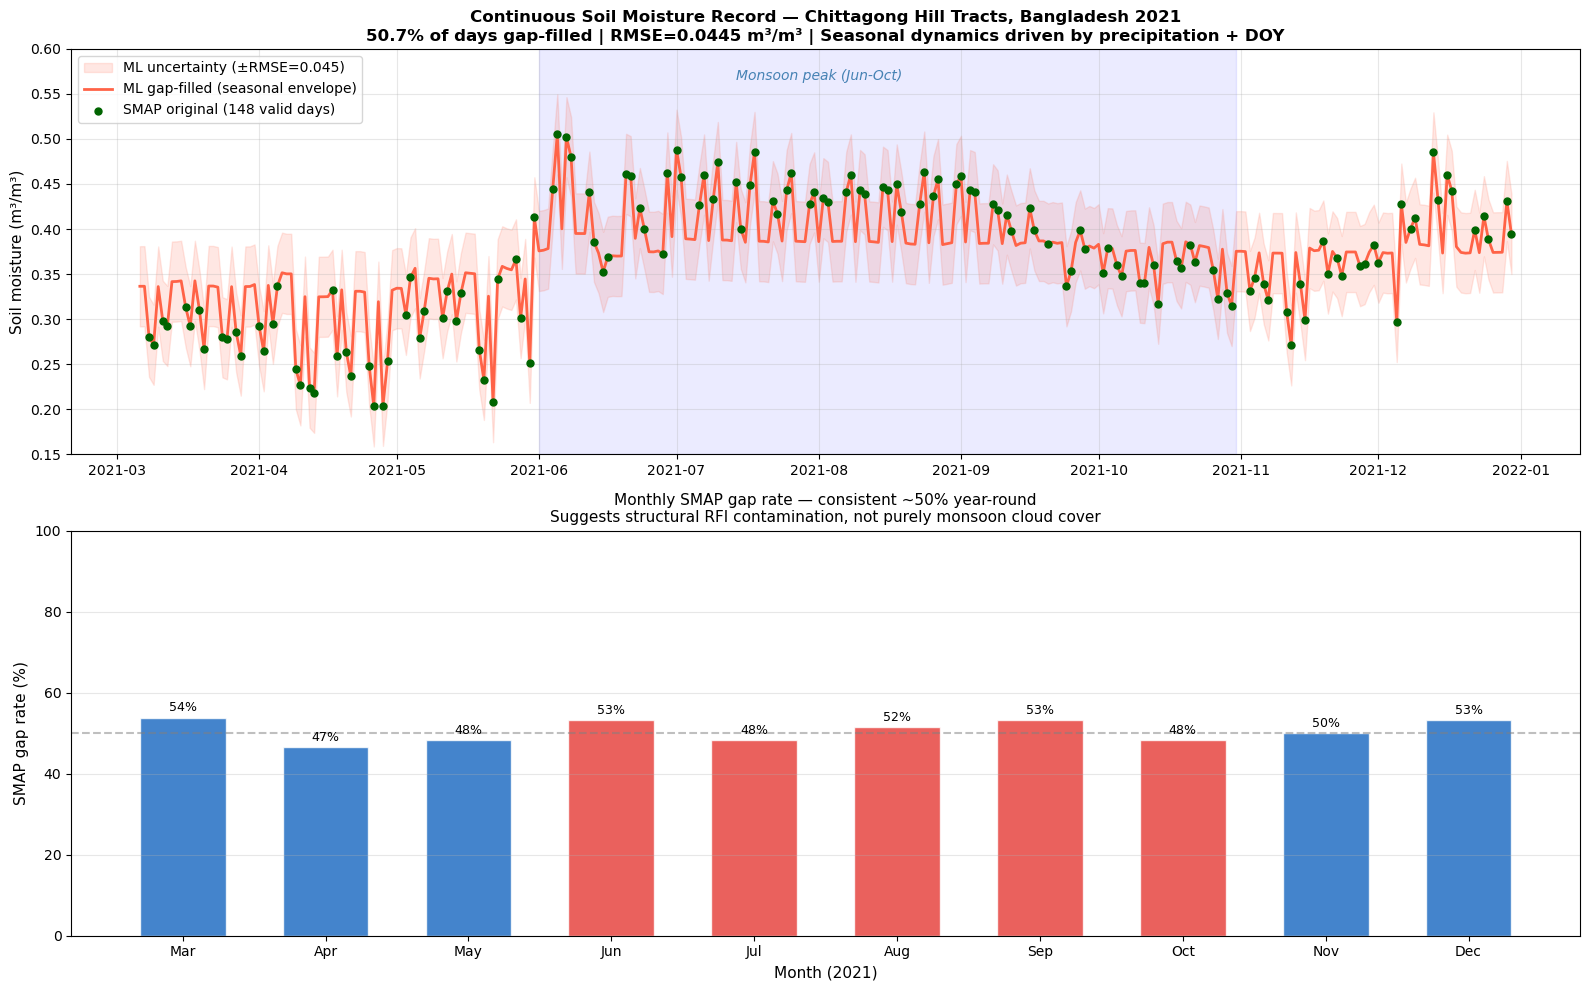

Saved to results/final_result.png


In [14]:
# Cell 6 — Final result plot
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

ax = axes[0]
ax.axvspan(pd.Timestamp('2021-06-01'), pd.Timestamp('2021-10-31'),
           alpha=0.08, color='blue')
ax.text(pd.Timestamp('2021-08-01'), 0.565,
        'Monsoon peak (Jun-Oct)', ha='center',
        fontsize=10, color='steelblue', style='italic')

ax.fill_between(ts['date'],
                ts['SMAP_complete'] - rmse,
                ts['SMAP_complete'] + rmse,
                alpha=0.15, color='tomato',
                label=f'ML uncertainty (±RMSE={rmse:.3f})')
ax.plot(ts['date'], ts['SMAP_complete'],
        color='tomato', lw=2, zorder=3,
        label='ML gap-filled (seasonal envelope)')

valid_ts = ts[ts['SMAP_SM'].notna()]
ax.scatter(valid_ts['date'], valid_ts['SMAP_SM'],
           color='darkgreen', s=25, zorder=5,
           label=f'SMAP original ({len(valid_ts)} valid days)')

ax.set_ylabel('Soil moisture (m³/m³)', fontsize=11)
ax.set_title(
    'Continuous Soil Moisture Record — Chittagong Hill Tracts, Bangladesh 2021\n'
    f'50.7% of days gap-filled | RMSE={rmse:.4f} m³/m³ | '
    f'Seasonal dynamics driven by precipitation + DOY',
    fontsize=12, fontweight='bold'
)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0.15, 0.60)

ax2 = axes[1]
ts['month'] = ts['date'].dt.month
ts['is_gap_flag'] = ts['SMAP_SM'].isna() & ts['SMAP_filled'].notna()

monthly = ts.groupby('month').agg(
    total=('date', 'count'),
    gaps=('is_gap_flag', 'sum')
).reset_index()
monthly['gap_pct'] = monthly['gaps'] / monthly['total'] * 100
month_names = ['Mar','Apr','May','Jun','Jul',
               'Aug','Sep','Oct','Nov','Dec']
colors = ['#E53935' if m >= 6 and m <= 10 else '#1565C0'
          for m in monthly['month']]

bars = ax2.bar(month_names, monthly['gap_pct'],
               color=colors, alpha=0.8,
               edgecolor='white', width=0.6)
for bar, pct in zip(bars, monthly['gap_pct']):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1.5,
             f'{pct:.0f}%', ha='center', fontsize=9)

ax2.axhline(50, color='gray', linestyle='--', alpha=0.5)
ax2.set_ylabel('SMAP gap rate (%)', fontsize=11)
ax2.set_xlabel('Month (2021)', fontsize=11)
ax2.set_title(
    'Monthly SMAP gap rate — consistent ~50% year-round\n'
    'Suggests structural RFI contamination, not purely monsoon cloud cover',
    fontsize=11
)
ax2.set_ylim(0, 100)
ax2.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('results/final_result.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to results/final_result.png")

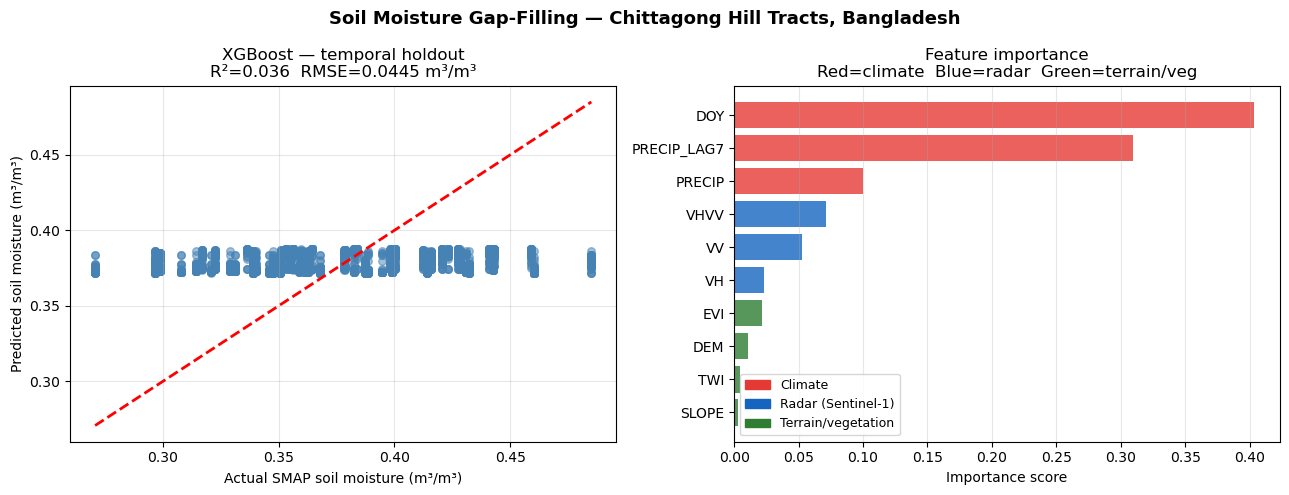

Saved to results/model_performance_final.png


In [15]:
# Cell 7 — Model performance plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5, color='steelblue', s=30)
axes[0].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual SMAP soil moisture (m³/m³)')
axes[0].set_ylabel('Predicted soil moisture (m³/m³)')
axes[0].set_title(f'XGBoost — temporal holdout\n'
                  f'R²={r2:.3f}  RMSE={rmse:.4f} m³/m³')
axes[0].grid(True, alpha=0.3)

feat_imp = sorted(zip(feature_cols, model.feature_importances_),
                  key=lambda x: x[1])
names, imps = zip(*feat_imp)
colors = ['#E53935' if n in ['DOY','PRECIP_LAG7','PRECIP']
          else '#1565C0' if n in ['VV','VH','VHVV']
          else '#2E7D32'
          for n in names]
axes[1].barh(names, imps, color=colors, alpha=0.8)
axes[1].set_xlabel('Importance score')
axes[1].set_title('Feature importance\n'
                  'Red=climate  Blue=radar  Green=terrain/veg')
axes[1].grid(True, alpha=0.3, axis='x')

from matplotlib.patches import Patch
legend = [Patch(color='#E53935', label='Climate'),
          Patch(color='#1565C0', label='Radar (Sentinel-1)'),
          Patch(color='#2E7D32', label='Terrain/vegetation')]
axes[1].legend(handles=legend, fontsize=9)

plt.suptitle('Soil Moisture Gap-Filling — Chittagong Hill Tracts, Bangladesh',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('results/model_performance_final.png', dpi=150,
            bbox_inches='tight')
plt.show()
print("Saved to results/model_performance_final.png")

In [16]:
# Cell 8 — Save requirements.txt and show project structure
reqs = [
    "earthengine-api>=0.1.370",
    "geemap>=0.30.0",
    "xgboost>=2.0.0",
    "scikit-learn>=1.3.0",
    "matplotlib>=3.7.0",
    "pandas>=2.0.0",
    "numpy>=1.24.0",
    "shap>=0.44.0",
    "notebook>=7.0.0",
]
with open('requirements.txt', 'w') as f:
    f.write("\n".join(reqs))
print("requirements.txt saved!")

print("\nProject files:")
for root, dirs, files in os.walk('.'):
    dirs[:] = [d for d in dirs
               if d not in ['.ipynb_checkpoints',
                             '__pycache__', '.git']]
    level = root.replace('.','').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files:
        print(f"{indent}  {file}")

requirements.txt saved!

Project files:
./
  Global forest soil moisture gap-filling with Google Earth Engine
  project 1
  Project_1.ipynb
  README.md
  requirements.txt
  .virtual_documents/
    Global forest soil moisture gap-filling with Google Earth Engine.ipynb
  data/
    cht_temporal_samples_v2.csv
    cht_temporal_with_smap.csv
    cht_training_data.csv
    cht_training_data_v2.csv
    cht_training_final.csv
    smap_daily_means.csv
  results/
    before_after_map.png
    before_after_map_v2.png
    cht_temporal_samples_v2.csv
    cht_temporal_with_smap.csv
    final_result.png
    gap_analysis.png
    interactive_map.html
    model_performance.png
    model_performance_final.png
    model_performance_v2.png
    shap_analysis.png
    temporal_gap_filling.png
    temporal_gap_filling_v2.png


In [17]:
import os
import shutil

# ── Files to KEEP in results/ ─────────────────────────────────────────
keep_results = {
    'final_result.png',
    'model_performance_final.png',
    'shap_analysis.png',
}

# ── Files to KEEP in data/ ────────────────────────────────────────────
keep_data = {
    'cht_temporal_with_smap.csv',
    'smap_daily_means.csv',
}

# ── Clean results/ ────────────────────────────────────────────────────
for f in os.listdir('results'):
    if f not in keep_results:
        os.remove(f'results/{f}')
        print(f"Removed results/{f}")

# ── Clean data/ ───────────────────────────────────────────────────────
for f in os.listdir('data'):
    if f not in keep_data:
        os.remove(f'data/{f}')
        print(f"Removed data/{f}")

# ── Remove stray files from root ──────────────────────────────────────
stray = ['Global forest soil moisture gap-filling with Google Earth Engine',
         'project 1']
for f in stray:
    if os.path.exists(f):
        if os.path.isdir(f):
            shutil.rmtree(f)
        else:
            os.remove(f)
        print(f"Removed {f}")

print("\nFinal project structure:")
for root, dirs, files in os.walk('.'):
    dirs[:] = [d for d in dirs
               if d not in ['.ipynb_checkpoints',
                             '__pycache__', '.git',
                             '.virtual_documents']]
    level = root.replace('.','').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files:
        print(f"{indent}  {file}")

Removed results/before_after_map.png
Removed results/before_after_map_v2.png
Removed results/cht_temporal_samples_v2.csv
Removed results/cht_temporal_with_smap.csv
Removed results/gap_analysis.png
Removed results/interactive_map.html
Removed results/model_performance.png
Removed results/model_performance_v2.png
Removed results/temporal_gap_filling.png
Removed results/temporal_gap_filling_v2.png
Removed data/cht_temporal_samples_v2.csv
Removed data/cht_training_data.csv
Removed data/cht_training_data_v2.csv
Removed data/cht_training_final.csv
Removed Global forest soil moisture gap-filling with Google Earth Engine
Removed project 1

Final project structure:
./
  Project_1.ipynb
  README.md
  requirements.txt
  data/
    cht_temporal_with_smap.csv
    smap_daily_means.csv
  results/
    final_result.png
    model_performance_final.png
    shap_analysis.png
